# Red and White Wine Quality: Models and Preprocessing Experiments
CSCI323 Modern AI · Group FT13
## Project Aim

This project investigates how data preprocessing and imbalance-handling strategies affect wine-quality prediction. We use 11 physicochemical measurements to predict numerical quality scores, training red and white wine models separately.

Rather than only identifying the highest-performing model, we examine **what changes, why it may matter, and how it affects predictions for both common and rare quality scores**.

## Models

We investigate four meaningfully different regression methods:

- **Linear Regression:** a simple linear reference.
- **Random Forest:** averages predictions from multiple decision trees.
- **KNN:** predicts using chemically similar training wines.
- **MLP Neural Network:** learns nonlinear relationships through connected layers.

The main preprocessing experiments keep each model’s previously selected settings fixed to help isolate the effect of changing the data treatment.

## Experimental Overview

| Experiment | Models | Question |
|---|---|---|
| **Reference evaluation** | All four | How do the selected models perform before changing preprocessing? |
| **Feature scaling** | KNN and MLP | How do no scaling, standard scaling and robust scaling affect predictions? |
| **Log transformation** | All four | Does transforming skewed chemical inputs improve performance? |
| **Feature subsets** | All four | What happens when we use 3, 5, 8 or all 11 features? |
| **Random oversampling** | All four | Does increasing rare-score representation improve their predictions? |
| **Sample weighting** | LR and RF | How do softer and stronger penalties on rare-score observations affect errors? |
| **RF regression versus classification** | RF | How does the target formulation change numerical errors and prediction accuracy? |
| **Feature importance** | RF regressor | Which chemical inputs does the fitted model rely on? |

## Data Preparation and Evaluation

Exact duplicate records are removed before creating separate, stratified 80/20 training–test splits with random seed 42. Every experiment uses the same split and shuffled five-fold cross-validation partitions within each wine dataset.

Preprocessing and feature selection are fitted within training partitions. Oversampling and weight calculation use training observations only; validation and test distributions remain unchanged. For MLP, the internal early-stopping validation set is separated before preprocessing and oversampling.

Oversampling raises small score groups to a minimum count equal to **10% of the original fitting-partition size**. Weighting uses normalised inverse score frequencies, with a softer square-root version and a stronger full version.

## Performance Measures

We report:

- **MAE, RMSE and R²** for overall prediction performance.
- **Macro MAE**, giving each observed quality score equal importance.
- **Per-score MAE and sample counts**, showing performance at individual quality levels.
- **Rare-score MAE** for quality ≤4 or ≥8, **typical-score MAE** for quality 5–6, and quality-7 MAE separately.

Cross-validation summaries combine out-of-fold predictions before calculating metrics. The RF formulation experiment also reports exact and within-one-score accuracy, using rounded regression predictions for those accuracy measures.

## Interpretation and Limitations

Improving rare-score predictions may worsen overall accuracy. Oversampling repeats existing records and does not create new independent information. Very small extreme-score groups require cautious interpretation.

The reference settings were selected during earlier development, so these experiments are conditional comparisons rather than nested evaluations of the complete selection process. The test set has also been inspected previously; holdout comparisons are therefore exploratory. Small differences do not establish statistical significance, and feature importance does not establish causation.

## Research Basis

Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016

This article supports the wine-quality regression problem. Our model configurations and experimental procedure differ from the original study.

## 1. Setup and data preparation
### 1.1 Libraries and reproducibility
Keep QUICK_MODE=False for report experiments. Quick mode uses fewer folds, trees and MLP epochs solely to check execution. The output files record versions and settings. MLP uses a validation split created before any resampling, with validation-MAE stopping; its scores must be regenerated and may differ from the older notebook.

In [ ]:
import importlib.util
import subprocess
import sys

required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import copy
import json
import platform
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if isinstance(value, pd.DataFrame) else value)
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

SEED = 42
QUICK_MODE = False
N_SPLITS = 2 if QUICK_MODE else 5
RF_TREES = 20 if QUICK_MODE else 200
MLP_MAX_EPOCHS = 8 if QUICK_MODE else 1000
MLP_PATIENCE = 3 if QUICK_MODE else 30
RUN_HOLDOUT = True
RUN_RF_GRID_SEARCH = True
OUTPUT = Path("wine_section_outputs")
OUTPUT.mkdir(exist_ok=True)
MODEL_NAMES = ["LR", "RF", "KNN", "MLP"]
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "sklearn": sklearn.__version__}
print(versions)
print("QUICK MODE:", QUICK_MODE, "| folds:", N_SPLITS)
print("Separate RF grid searches:", RUN_RF_GRID_SEARCH)
if QUICK_MODE:
    print("Execution check only: do not report quick-mode results as final experiments.")
config = dict(seed=SEED, quick_mode=QUICK_MODE, folds=N_SPLITS, rf_trees=RF_TREES,
              mlp_max_epochs=MLP_MAX_EPOCHS, mlp_patience=MLP_PATIENCE,
              run_holdout=RUN_HOLDOUT, run_rf_grid_search=RUN_RF_GRID_SEARCH,
              versions=versions)
(OUTPUT / "run_configuration.json").write_text(json.dumps(config, indent=2))

### 1.2 Load and clean red wine
Download the original red-wine CSV (or use data/winequality-red.csv), check missingness, and remove exact duplicate rows before splitting. Original row identities are retained. Duplicate removal prevents identical feature-and-target records entering both train and test; duplicates are not automatically measurement errors.

In [ ]:
BASE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
red_local = Path("data/winequality-red.csv")
red_original = pd.read_csv(red_local if red_local.exists() else BASE_URL + "winequality-red.csv", sep=";")
assert not red_original.isna().any().any()
red_clean = red_original.drop_duplicates().copy()
red_cleaning = pd.DataFrame([{"Dataset":"Red", "Original":len(red_original),
    "Removed":len(red_original)-len(red_clean), "Remaining":len(red_clean)}])
display(red_cleaning)
display(red_clean.head())

,Dataset,Original,Removed,Remaining
0,Red,1599,240,1359


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


### 1.3 Load and clean white wine
Apply the identical cleaning policy to white wine. It remains a separate dataset throughout the notebook.

In [ ]:
white_local = Path("data/winequality-white.csv")
white_original = pd.read_csv(white_local if white_local.exists() else BASE_URL + "winequality-white.csv", sep=";")
assert not white_original.isna().any().any()
white_clean = white_original.drop_duplicates().copy()
white_cleaning = pd.DataFrame([{"Dataset":"White", "Original":len(white_original),
    "Removed":len(white_original)-len(white_clean), "Remaining":len(white_clean)}])
display(white_cleaning)
display(white_clean.head())

,Dataset,Original,Removed,Remaining
0,White,4898,937,3961


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6


### 1.4 Combined cleaning and target-distribution comparison
Compare the original and remaining sample counts and the cleaned quality distributions. This is descriptive analysis, not model evaluation.

,Dataset,Original,Removed,Remaining
0,Red,1599,240,1359
1,White,4898,937,3961


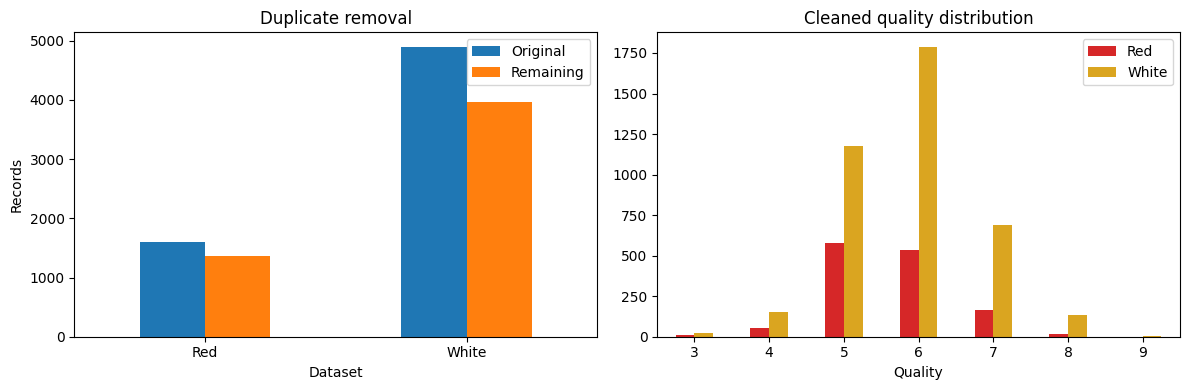

,Quality,Red,White
0,3,10.0,20
1,4,53.0,153
2,5,577.0,1175
3,6,535.0,1788
4,7,167.0,689
5,8,17.0,131
6,9,0.0,5


In [ ]:
cleaning_df = pd.concat([red_cleaning,white_cleaning],ignore_index=True)
display(cleaning_df)
assert cleaning_df.Remaining.tolist()==[1359,3961]
fig,axes=plt.subplots(1,2,figsize=(12,4))
cleaning_df.set_index("Dataset")[["Original","Remaining"]].plot.bar(ax=axes[0],rot=0)
axes[0].set_title("Duplicate removal");axes[0].set_ylabel("Records")
quality_distribution = pd.DataFrame({"Red":red_clean.quality.value_counts(),
    "White":white_clean.quality.value_counts()}).fillna(0).sort_index()
quality_distribution.plot.bar(ax=axes[1],color=["tab:red","goldenrod"],rot=0)
axes[1].set_title("Cleaned quality distribution");axes[1].set_xlabel("Quality")
plt.tight_layout();plt.savefig(OUTPUT/"cleaning_distribution.png",dpi=200);plt.show();plt.close("all")
display(quality_distribution.rename_axis("Quality").reset_index())
cleaning_df.to_csv(OUTPUT/"cleaning_counts.csv",index=False)

### 1.5 Red wine — train/test split
Use all 11 chemical inputs and quality as the numerical target. Stratify the 80/20 split by score, with seed 42. This holdout split is distinct from the shuffled, non-stratified KFold splits used for training-set CV.

In [ ]:
X = red_clean.drop(columns="quality"); y = red_clean.quality
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED,stratify=y)
print("Red training:",X_train.shape,"| test:",X_test.shape)
assert set(X_train.index).isdisjoint(X_test.index)

Red training: (1087, 11) | test: (272, 11)


### 1.6 White wine — train/test split
Use the same split policy independently for white wine. Never fit preprocessing jointly across the red and white datasets.

In [ ]:
white_X = white_clean.drop(columns="quality"); white_y = white_clean.quality
white_X_train,white_X_test,white_y_train,white_y_test = train_test_split(
    white_X,white_y,test_size=0.2,random_state=SEED,stratify=white_y)
print("White training:",white_X_train.shape,"| test:",white_X_test.shape)
assert set(white_X_train.index).isdisjoint(white_X_test.index)

White training: (3168, 11) | test: (793, 11)


### 1.7 Combined split comparison and shared folds
Save the row identities and generate CV partitions once per dataset. All experiments below reuse these exact partitions. Test observations retain their natural score distribution.

,Dataset,Training,Testing
0,Red,1087,272
1,White,3168,793


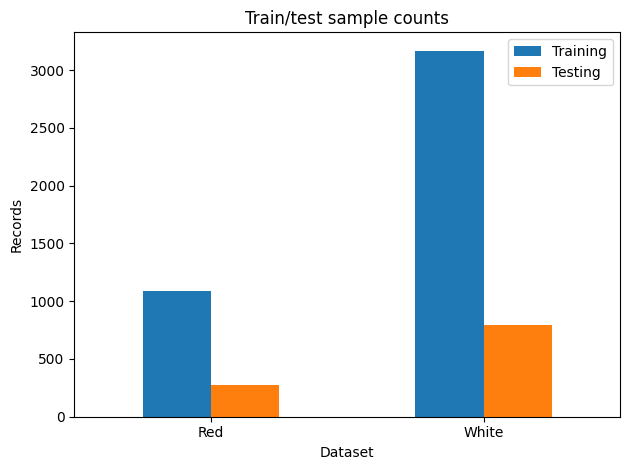

In [ ]:
DATASETS = {"Red":(X_train,X_test,y_train,y_test),
            "White":(white_X_train,white_X_test,white_y_train,white_y_test)}
SPLITS = {wine:list(KFold(n_splits=N_SPLITS,shuffle=True,random_state=SEED).split(data[0]))
          for wine,data in DATASETS.items()}
split_table = pd.DataFrame([{"Dataset":wine,"Training":len(data[2]),"Testing":len(data[3])}
                           for wine,data in DATASETS.items()])
display(split_table)
split_table.set_index("Dataset").plot.bar(rot=0,title="Train/test sample counts")
plt.ylabel("Records");plt.tight_layout();plt.show();plt.close("all")
split_records=[]
for wine,(a,b,c,d) in DATASETS.items():
    assert a.shape[1]==11 and (a>=0).all().all()
    for partition,target in [("Train",c),("Test",d)]:
        split_records.extend({"Dataset":wine,"Partition":partition,"Source row":int(i),"Quality":int(q)}
                             for i,q in target.items())
pd.DataFrame(split_records).to_csv(OUTPUT/"split_row_ids.csv",index=False)

## 2. Shared training and evaluation rules
### 2.1 Preprocessing, weighting, oversampling and MLP validation
These common helpers prevent methodological differences between the red and white calculation cells. Each later section explicitly names the condition being tested.

Log-column selection (skewness >1) and SelectKBest feature selection are learned inside the current fitting partition. Scaling is used for KNN/MLP, not RF/LR. Feature ranking is univariate and can miss interactions.

Weights are normalised inverse score frequencies (power 0.5 or 1). Oversampling raises small score-group counts to floor(10% of the original fitting-partition size), not 10% of the enlarged final dataset. It can include score 7.

For MLP, an untouched 15% inner validation set is separated first. Preprocessing is fitted on the remaining records; oversampling is applied only after this split and scaling. Explicit epoch-by-epoch training restores the parameters with lowest inner validation MAE. Thus duplicate copies cannot cross into the inner validation set. MLP weighting is outside the chosen matrix; standard KNN has no training sample weights.

In [ ]:
def score_weights(y, power):
    y = pd.Series(np.asarray(y))
    w = np.power(1.0 / y.map(y.value_counts(normalize=True)).to_numpy(), power)
    return w / w.mean()

def oversample_indices(y, minimum_fraction=0.10, seed=SEED):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    indices = list(range(len(y)))
    target = int(np.floor(minimum_fraction * len(y)))
    for q in np.unique(y):
        available = np.flatnonzero(y == q)
        need = max(0, target - len(available))
        if need:
            indices.extend(rng.choice(available, size=need, replace=True).tolist())
    indices = np.asarray(indices, dtype=int)
    rng.shuffle(indices)
    return indices

class WineRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, model_name="RF", wine="Red", representation="raw", treatment="Original",
                 scaling="standard", seed=SEED):
        self.model_name = model_name
        self.wine = wine
        self.representation = representation
        self.treatment = treatment
        self.scaling = scaling
        self.seed = seed

    def _represent(self, X):
        Z = X.loc[:, self.columns_].astype(float).copy()
        if (Z < 0).any().any():
            raise ValueError("This preprocessing expects nonnegative wine measurements.")
        for col, method in self.log_methods_.items():
            Z[col] = np.log1p(Z[col]) if method == "log1p" else np.log(Z[col].clip(lower=1e-6))
        return Z.to_numpy()

    def _fit_preprocessing(self, X, y):
        self.columns_ = list(X.columns)
        self.log_methods_ = {}
        if self.representation == "log":
            for col in X.columns[X.skew() > 1.0]:
                self.log_methods_[col] = "log1p" if (X[col] <= 0).any() else "log"
        elif self.representation.startswith("top"):
            k = int(self.representation[3:])
            selector = SelectKBest(f_regression, k=k).fit(X, y)
            self.columns_ = X.columns[selector.get_support()].tolist()
        elif self.representation != "raw":
            raise ValueError(self.representation)
        A = self._represent(X)
        self.scaler_ = None
        if self.model_name in ["KNN", "MLP"]:
            if self.scaling == "standard": self.scaler_ = StandardScaler()
            elif self.scaling == "robust": self.scaler_ = RobustScaler()
            elif self.scaling != "none": raise ValueError(self.scaling)
        if self.scaler_ is not None:
            A = self.scaler_.fit_transform(A)
        return A

    def _transform(self, X):
        A = self._represent(X)
        return self.scaler_.transform(A) if self.scaler_ is not None else A

    def fit(self, X, y):
        X = X.copy(); y = np.asarray(y, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        fit_positions = np.arange(len(y))
        self.inner_validation_positions_ = np.array([], dtype=int)
        if self.model_name == "MLP":
            fit_positions, val_positions = train_test_split(fit_positions, test_size=0.15, random_state=self.seed)
            self.inner_validation_positions_ = val_positions
            Xfit, yfit = X.iloc[fit_positions], y[fit_positions]
        else:
            Xfit, yfit = X, y
        A = self._fit_preprocessing(Xfit, yfit)
        self.original_fit_count_ = len(yfit)
        self.pre_counts_ = pd.Series(yfit).value_counts().sort_index().to_dict()
        w = None
        used = np.arange(len(yfit))
        if self.treatment == "Oversample":
            used = oversample_indices(yfit, seed=self.seed)
            A, yfit = A[used], yfit[used]
        elif self.treatment in ["Weight soft", "Weight full"]:
            if self.model_name not in ["LR", "RF"]:
                raise ValueError("Weighting is defined only for LR/RF in this experiment matrix.")
            w = score_weights(yfit, 0.5 if self.treatment == "Weight soft" else 1.0)
        elif self.treatment != "Original": raise ValueError(self.treatment)
        self.fit_source_positions_ = fit_positions[used]
        assert not np.intersect1d(self.fit_source_positions_, self.inner_validation_positions_).size
        self.post_counts_ = pd.Series(yfit).value_counts().sort_index().to_dict()
        if self.model_name == "LR":
            self.model_ = LinearRegression().fit(A, yfit, sample_weight=w)
        elif self.model_name == "RF":
            self.model_ = RandomForestRegressor(n_estimators=RF_TREES,
                max_depth=None if self.wine == "Red" else 20, min_samples_leaf=3,
                random_state=self.seed, n_jobs=-1).fit(A, yfit, sample_weight=w)
        elif self.model_name == "KNN":
            self.model_ = KNeighborsRegressor(n_neighbors=11 if self.wine == "Red" else 15,
                weights="distance", p=1).fit(A, yfit)
        elif self.model_name == "MLP":
            Aval, yval = self._transform(X.iloc[val_positions]), y[val_positions]
            self.model_ = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                alpha=0.001, learning_rate_init=0.001, early_stopping=False,
                random_state=self.seed, shuffle=True)
            self.history_ = []
            best_error, wait, state = np.inf, 0, None
            for epoch in range(1, MLP_MAX_EPOCHS + 1):
                self.model_.partial_fit(A, yfit)
                err = mean_absolute_error(yval, self.model_.predict(Aval))
                self.history_.append(err)
                if err < best_error - 1e-4:
                    best_error, wait = err, 0
                    state = (copy.deepcopy(self.model_.coefs_), copy.deepcopy(self.model_.intercepts_))
                    self.best_epoch_ = epoch
                else:
                    wait += 1
                if wait >= MLP_PATIENCE: break
            self.model_.coefs_, self.model_.intercepts_ = state
            self.epochs_run_ = epoch
        else: raise ValueError(self.model_name)
        return self

    def predict(self, X):
        return self.model_.predict(self._transform(X))

### 2.2 Metrics and reusable fold evaluation
MAE is average absolute error; RMSE penalises large errors; R² can be negative. Macro MAE gives equal weight to each observed quality score. Rare MAE pools scores ≤4 or ≥8, typical MAE pools 5–6, and score 7 is reported separately. Per-score sample counts remain essential.

Each record receives one out-of-fold prediction. We pool those predictions to calculate CV summaries; fold MAE standard deviation is descriptive, not a significance test. Weighted squared-error fitting increases rare scores' contributions to LR training. Scaling changes KNN distances; a log transform changes feature spacing nonlinearly.

In [ ]:
def prediction_metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    errors = pd.DataFrame({"Quality": y, "Absolute error": np.abs(y-pred)})
    per_score = errors.groupby("Quality")["Absolute error"].mean()
    def group_mae(mask):
        return float(np.mean(np.abs(y[mask]-pred[mask]))) if mask.any() else np.nan
    return {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred), "Macro MAE": per_score.mean(),
            "Rare MAE": group_mae((y<=4)|(y>=8)),
            "Typical MAE": group_mae((y>=5)&(y<=6)), "Score 7 MAE": group_mae(y==7)}

def by_quality(y, pred):
    table = pd.DataFrame({"Quality": np.asarray(y), "Prediction": pred,
                          "Abs error": np.abs(np.asarray(y)-pred)})
    return table.groupby("Quality").agg(Samples=("Abs error", "size"),
        MAE=("Abs error", "mean"), Mean_prediction=("Prediction", "mean")).reset_index()


def estimator_for(wine, cfg):
    return WineRegressor(model_name=cfg["Model"], wine=wine,
        representation=cfg["Representation"], treatment=cfg["Treatment"], scaling=cfg["Scaling"])

def run_cv_configuration(wine, cfg):
    Xtr, _, ytr, _ = DATASETS[wine]
    oof = np.full(len(ytr), np.nan)
    fold_rows, counts, selected = [], [], []
    for fold, (itr, iva) in enumerate(SPLITS[wine], start=1):
        assert not np.intersect1d(itr, iva).size
        model = estimator_for(wine, cfg).fit(Xtr.iloc[itr], ytr.iloc[itr])
        pred = model.predict(Xtr.iloc[iva]); oof[iva] = pred
        fold_rows.append({"Fold": fold, **prediction_metrics(ytr.iloc[iva], pred)})
        for q in sorted(model.pre_counts_):
            counts.append({"Fold": fold, "Quality": q, "Before": model.pre_counts_[q],
                "After": model.post_counts_[q], "Factor": model.post_counts_[q]/model.pre_counts_[q]})
        selected.append({"Fold": fold, "Features": ", ".join(model.columns_),
            "Log functions": json.dumps(model.log_methods_),
            "MLP best epoch": getattr(model, "best_epoch_", np.nan)})
    assert np.isfinite(oof).all()
    pooled = prediction_metrics(ytr, oof)
    pooled["Fold MAE std"] = pd.DataFrame(fold_rows)["MAE"].std(ddof=0)
    return pooled, oof, fold_rows, counts, selected

### 2.3 Result storage and combined display helpers
Each experiment saves a combined red/white table and a graph immediately below its calculation cells. Within-model graphs compare preprocessing conditions; the overall reference graph compares the four methods. Intermediate files are exported after each completed condition.

In [ ]:
RESULT_CACHE = {}
ALL_CV_ROWS, ALL_TEST_ROWS, ALL_OOF_ROWS, ALL_TEST_PREDICTIONS = [],[],[],[]
ALL_FOLD_ROWS, ALL_COUNTS, ALL_PREPROCESSING = [],[],[]
REFERENCE_FITS = {}

def condition(wine, model, variant="Reference", representation="raw", treatment="Original", scaling="standard"):
    key=(wine,model,variant)
    if key in RESULT_CACHE:
        return RESULT_CACHE[key]
    cfg=dict(Model=model,Variant=variant,Representation=representation,Treatment=treatment,Scaling=scaling)
    tags={"Dataset":wine,**cfg,"Scaling":scaling if model in ["KNN","MLP"] else "Not applied"}
    metrics,pred,folds,counts,selected=run_cv_configuration(wine,cfg)
    row={**tags,**metrics};ALL_CV_ROWS.append(row)
    Xtr,Xte,ytr,yte=DATASETS[wine]
    ALL_OOF_ROWS.extend({**tags,"Source row":int(i),"Quality":float(q),"Prediction":float(p)}
                        for i,q,p in zip(Xtr.index,ytr,pred))
    ALL_FOLD_ROWS.extend({**tags,**r} for r in folds)
    ALL_COUNTS.extend({**tags,**r} for r in counts)
    ALL_PREPROCESSING.extend({**tags,**r} for r in selected)
    if RUN_HOLDOUT:
        fitted=estimator_for(wine,cfg).fit(Xtr,ytr)
        test_pred=fitted.predict(Xte)
        ALL_TEST_ROWS.append({**tags,**prediction_metrics(yte,test_pred),
            "MLP best epoch":getattr(fitted,"best_epoch_",np.nan)})
        ALL_TEST_PREDICTIONS.extend({**tags,"Source row":int(i),"Quality":float(q),"Prediction":float(p)}
                                   for i,q,p in zip(Xte.index,yte,test_pred))
        if variant=="Reference":REFERENCE_FITS[(wine,model)]=fitted
    RESULT_CACHE[key]=row
    save_progress()
    print(f"Completed: {wine} | {model} | {variant}")
    return row

def save_progress():
    for records,filename in [(ALL_CV_ROWS,"cv_summary.csv"),(ALL_TEST_ROWS,"exploratory_test_summary.csv"),
        (ALL_OOF_ROWS,"oof_predictions.csv"),(ALL_TEST_PREDICTIONS,"exploratory_test_predictions.csv"),
        (ALL_FOLD_ROWS,"fold_scores.csv"),(ALL_COUNTS,"sampling_counts.csv"),
        (ALL_PREPROCESSING,"fold_preprocessing.csv")]:
        if records:pd.DataFrame(records).to_csv(OUTPUT/filename,index=False)

def comparison(title, model, variants, metrics=("MAE","Macro MAE"), holdout=False):
    records=ALL_TEST_ROWS if holdout else ALL_CV_ROWS
    part=pd.DataFrame(records)
    part=part[(part.Model==model)&part.Variant.isin(variants)]
    if part.empty:return
    label="Exploratory test" if holdout else "Pooled OOF"
    display(part[["Dataset","Model","Variant","MAE","RMSE","R2","Macro MAE","Rare MAE","Typical MAE","Score 7 MAE"]].round(4))
    fig,axes=plt.subplots(1,len(metrics),figsize=(6*len(metrics),4.5),squeeze=False)
    for ax,metric in zip(axes[0],metrics):
        pivot=part.pivot(index="Variant",columns="Dataset",values=metric).reindex(variants)
        pivot=pivot.reindex(columns=["Red","White"])
        pivot.plot.bar(ax=ax,color=["tab:red","goldenrod"],rot=20)
        ax.set_title(f"{label} {metric}");ax.set_ylabel(metric);ax.set_xlabel("");ax.grid(axis="y",alpha=.25)
    fig.suptitle(title);plt.tight_layout()
    safe=''.join(c if c.isalnum() else '_' for c in title.lower())
    plt.savefig(OUTPUT/f"{safe}_{'test' if holdout else 'cv'}.png",dpi=200,bbox_inches="tight");plt.show();plt.close("all")

def score_comparison(wine,model,variants,title):
    records=pd.DataFrame(ALL_OOF_ROWS)
    part=records[(records.Dataset==wine)&(records.Model==model)&records.Variant.isin(variants)]
    tables=[]
    fig,ax=plt.subplots(figsize=(8,4.5))
    for variant in variants:
        d=part[part.Variant==variant]
        if d.empty:continue
        summary=by_quality(d.Quality.to_numpy(),d.Prediction.to_numpy())
        tables.append(summary.assign(Dataset=wine,Model=model,Variant=variant))
        ax.plot(summary.Quality,summary.MAE,marker="o",label=variant)
        if variant=="Reference":
            ax.set_xticks(summary.Quality)
            ax.set_xticklabels([f"{q:g}\n(n={n})" for q,n in zip(summary.Quality,summary.Samples)])
    ax.set_title(title);ax.set_xlabel("Actual quality / validation sample count");ax.set_ylabel("OOF MAE")
    ax.legend();ax.grid(alpha=.25);plt.tight_layout()
    plt.savefig(OUTPUT/f"{wine.lower()}_{model.lower()}_score_treatments.png",dpi=200,bbox_inches="tight");plt.show();plt.close("all")
    display(pd.concat(tables,ignore_index=True).round(4))

## 3. Reference models — implementation and evaluation
Each reference is calculated separately for red and white, followed by combined results. CV uses training records only. Holdout metrics, when enabled, are exploratory. The original-distribution selected configuration is called “Reference” throughout the new experiments, not an untuned default baseline.

### 3.1 Linear Regression
All 11 inputs, fitted intercept and no polynomial expansion. This simple linear reference minimises squared training errors. It does not require scaling to preserve its fitted predictions under an invertible linear feature rescaling.

#### Red wine — calculations

In [ ]:
red_lr_reference = condition("Red","LR")
display(pd.DataFrame([red_lr_reference]).round(4))

Completed: Red | LR | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,LR,Reference,raw,Original,Not applied,0.516,0.6674,0.3445,1.088,1.4906,0.4002,0.8188,0.0251


#### White wine — calculations

In [ ]:
white_lr_reference = condition("White","LR")
display(pd.DataFrame([white_lr_reference]).round(4))

Completed: White | LR | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,LR,Reference,raw,Original,Not applied,0.5776,0.746,0.2983,1.4217,1.5839,0.4311,0.7567,0.0183


#### Combined results
Compare red and white errors for this reference model. Dataset differences are descriptive because sample sizes and target distributions differ.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188
1,White,LR,Reference,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567


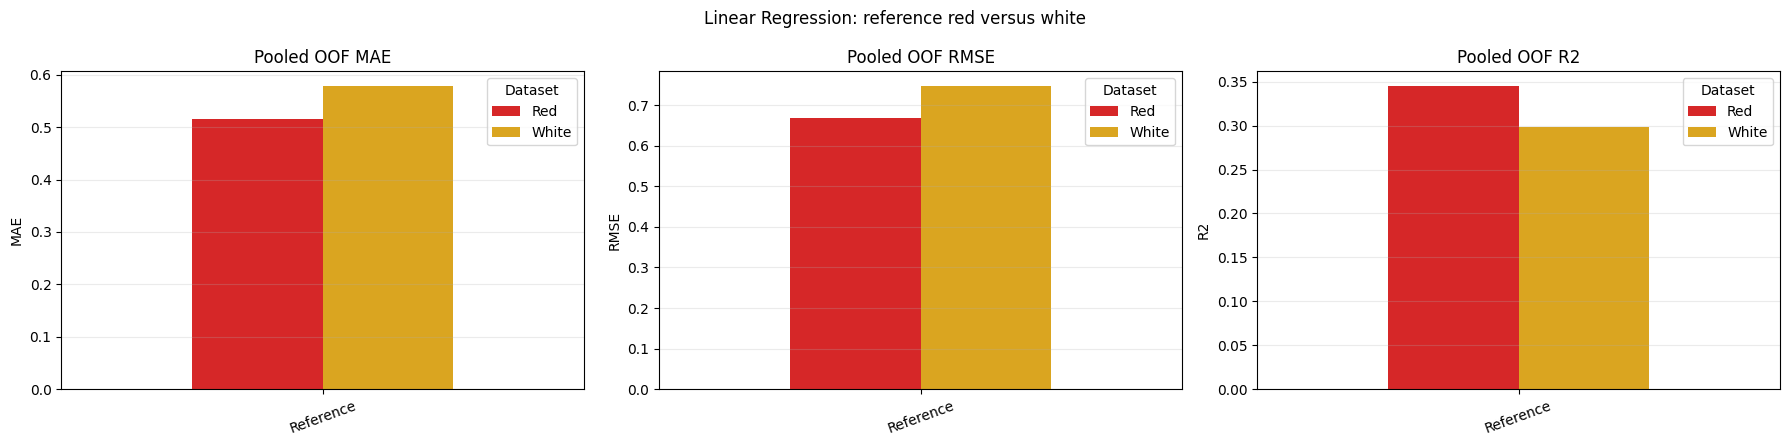

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5066,0.6523,0.3657,1.1082,1.3838,0.3998,0.8027
1,White,LR,Reference,0.5867,0.7608,0.2703,1.3764,1.6438,0.4448,0.7217


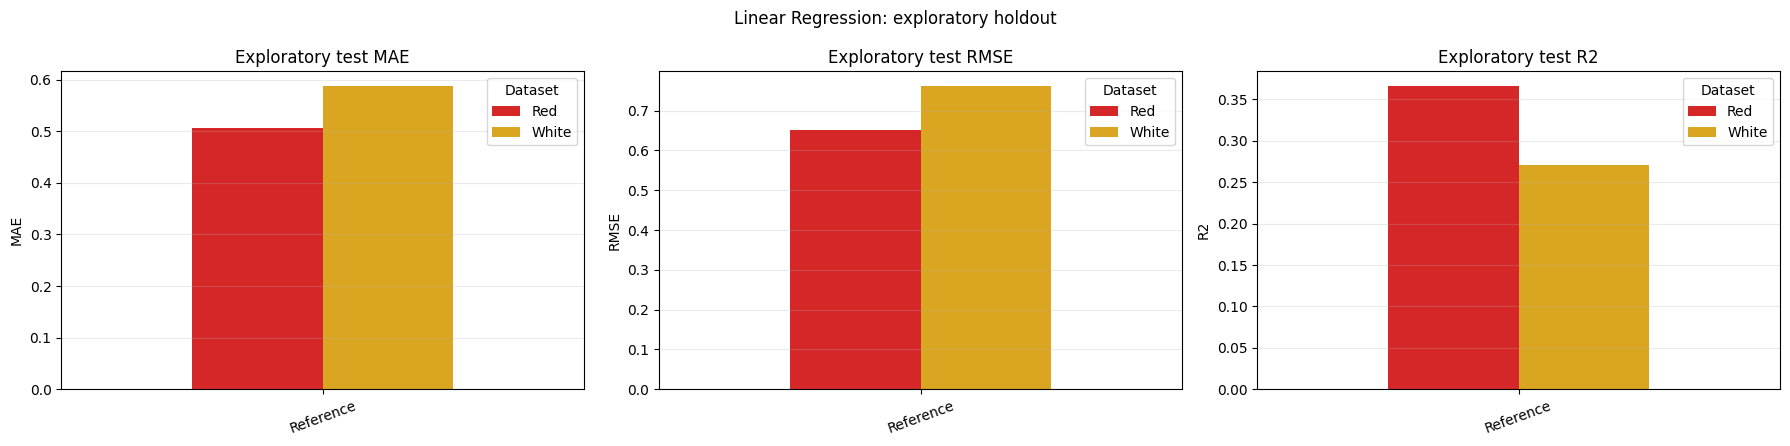

In [ ]:
comparison("Linear Regression: reference red versus white","LR",["Reference"],metrics=("MAE","RMSE","R2"))
if RUN_HOLDOUT:
    comparison("Linear Regression: exploratory holdout","LR",["Reference"],metrics=("MAE","RMSE","R2"),holdout=True)

### 3.2 Random Forest
Previous selected settings: 200 trees, minimum leaf size 3, maximum depth None for red and 20 for white. The forest averages trees trained with bootstrap sampling and random feature subsets. These are fixed reference settings, not a new claim of optimality.

#### Red wine — calculations

In [ ]:
red_rf_reference = condition("Red","RF")
display(pd.DataFrame([red_rf_reference]).round(4))

Completed: Red | RF | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,RF,Reference,raw,Original,Not applied,0.4905,0.6408,0.3956,1.056,1.4454,0.3865,0.7241,0.0224


#### White wine — calculations

In [ ]:
white_rf_reference = condition("White","RF")
display(pd.DataFrame([white_rf_reference]).round(4))

Completed: White | RF | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,RF,Reference,raw,Original,Not applied,0.5414,0.7042,0.3747,1.333,1.442,0.4183,0.6669,0.0144


#### Combined results
Compare red and white errors for this reference model. Dataset differences are descriptive because sample sizes and target distributions differ.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4905,0.6408,0.3956,1.056,1.4454,0.3865,0.7241
3,White,RF,Reference,0.5414,0.7042,0.3747,1.333,1.4420,0.4183,0.6669


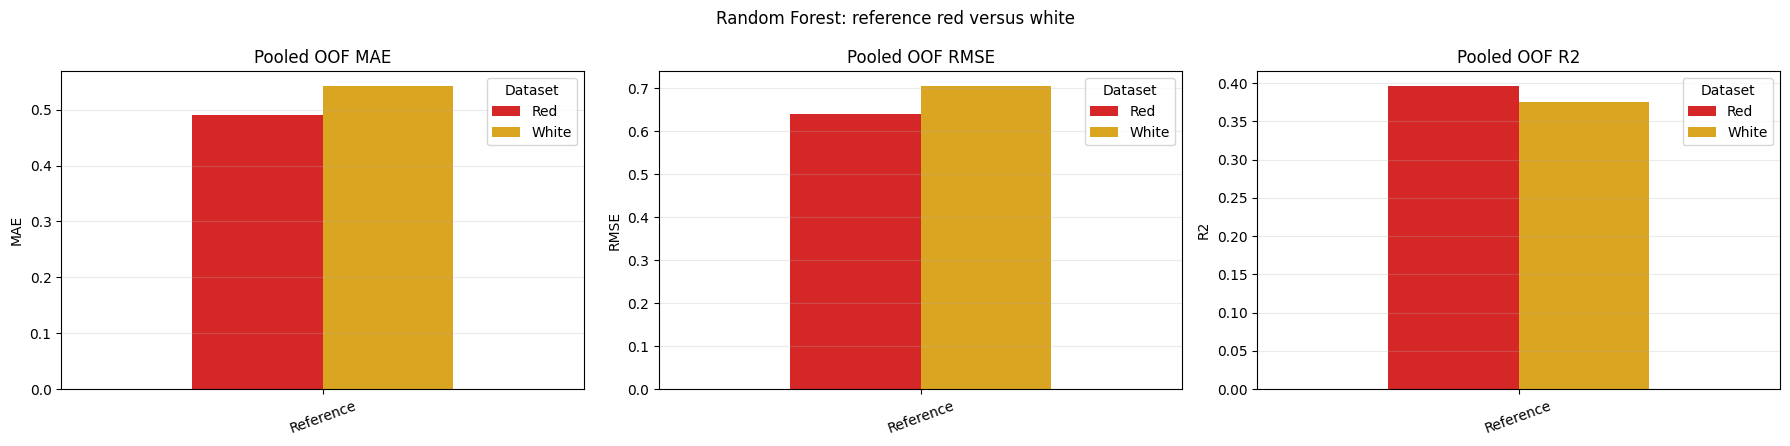

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226
3,White,RF,Reference,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633


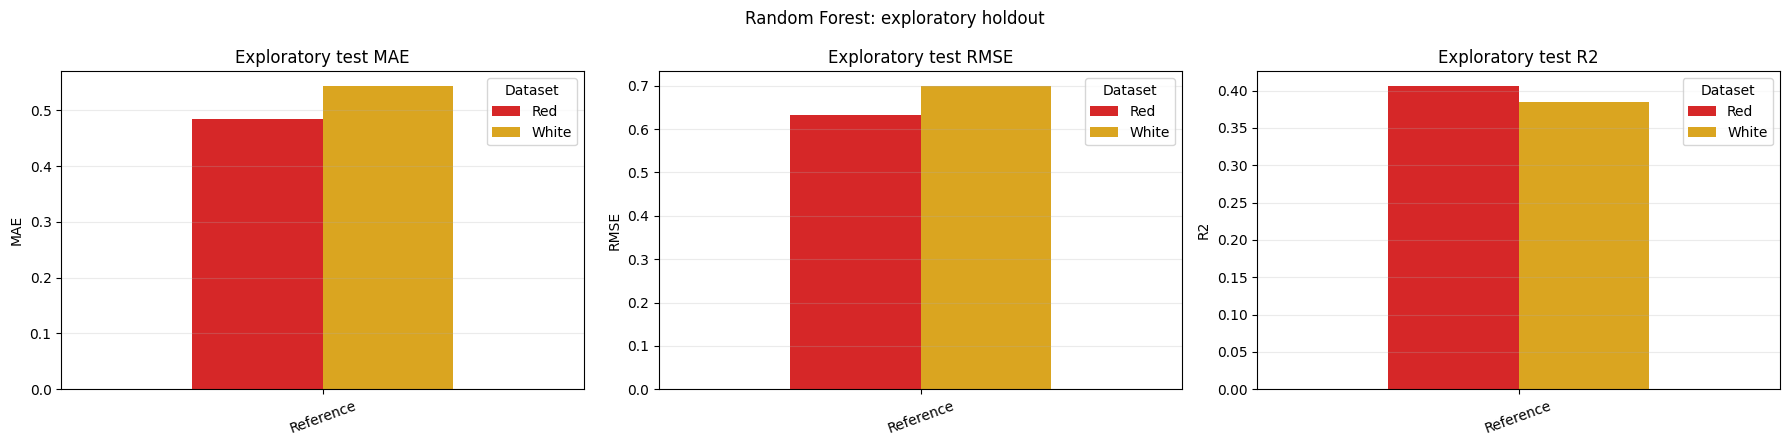

In [ ]:
comparison("Random Forest: reference red versus white","RF",["Reference"],metrics=("MAE","RMSE","R2"))
if RUN_HOLDOUT:
    comparison("Random Forest: exploratory holdout","RF",["Reference"],metrics=("MAE","RMSE","R2"),holdout=True)

### 3.3 KNN
Previous selected settings: k=11 red, k=15 white, distance weights and Manhattan distance. StandardScaler is fitted inside each fold. A perfect training score with distance weighting can follow from self-neighbours and neither proves nor rules out overfitting.

#### Red wine — calculations

In [ ]:
red_knn_reference = condition("Red","KNN")
display(pd.DataFrame([red_knn_reference]).round(4))

Completed: Red | KNN | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.528,0.4051,0.7664,0.0266


#### White wine — calculations

In [ ]:
white_knn_reference = condition("White","KNN")
display(pd.DataFrame([white_knn_reference]).round(4))

Completed: White | KNN | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104


#### Combined results
Compare red and white errors for this reference model. Dataset differences are descriptive because sample sizes and target distributions differ.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664
5,White,KNN,Reference,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651


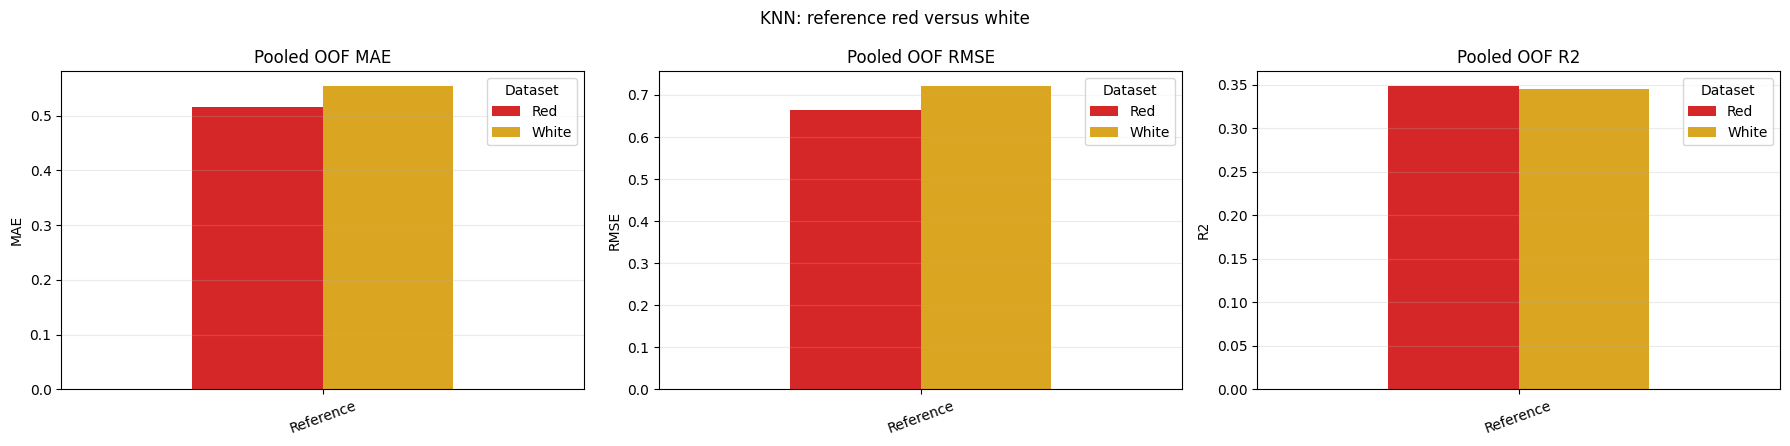

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5092,0.6651,0.3406,1.1350,1.4478,0.4062,0.7505
5,White,KNN,Reference,0.5563,0.7215,0.3438,1.3372,1.5924,0.4303,0.6323


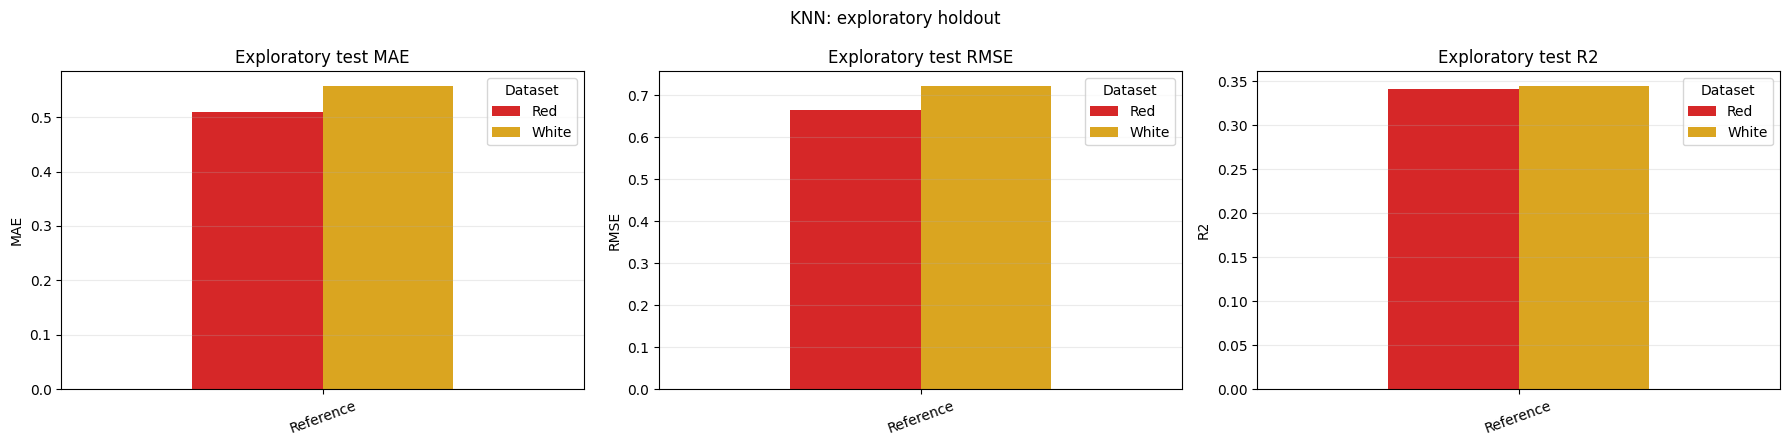

In [ ]:
comparison("KNN: reference red versus white","KNN",["Reference"],metrics=("MAE","RMSE","R2"))
if RUN_HOLDOUT:
    comparison("KNN: exploratory holdout","KNN",["Reference"],metrics=("MAE","RMSE","R2"),holdout=True)

### 3.4 MLP Neural Network
Two hidden layers (64,32), ReLU, Adam, alpha=0.001 and learning rate 0.001. Inputs are standardised within fitting partitions. A separate inner validation set determines when training stops. This corrected schedule differs from the old built-in early stopping; do not reuse old MLP scores.

#### Red wine — calculations

In [ ]:
red_mlp_reference = condition("Red","MLP")
display(pd.DataFrame([red_mlp_reference]).round(4))

Completed: Red | MLP | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.09,1.4919,0.4419,0.7534,0.0373


#### White wine — calculations

In [ ]:
white_mlp_reference = condition("White","MLP")
display(pd.DataFrame([white_mlp_reference]).round(4))

Completed: White | MLP | Reference


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113


#### Combined results
Compare red and white errors for this reference model. Dataset differences are descriptive because sample sizes and target distributions differ.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534
7,White,MLP,Reference,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803


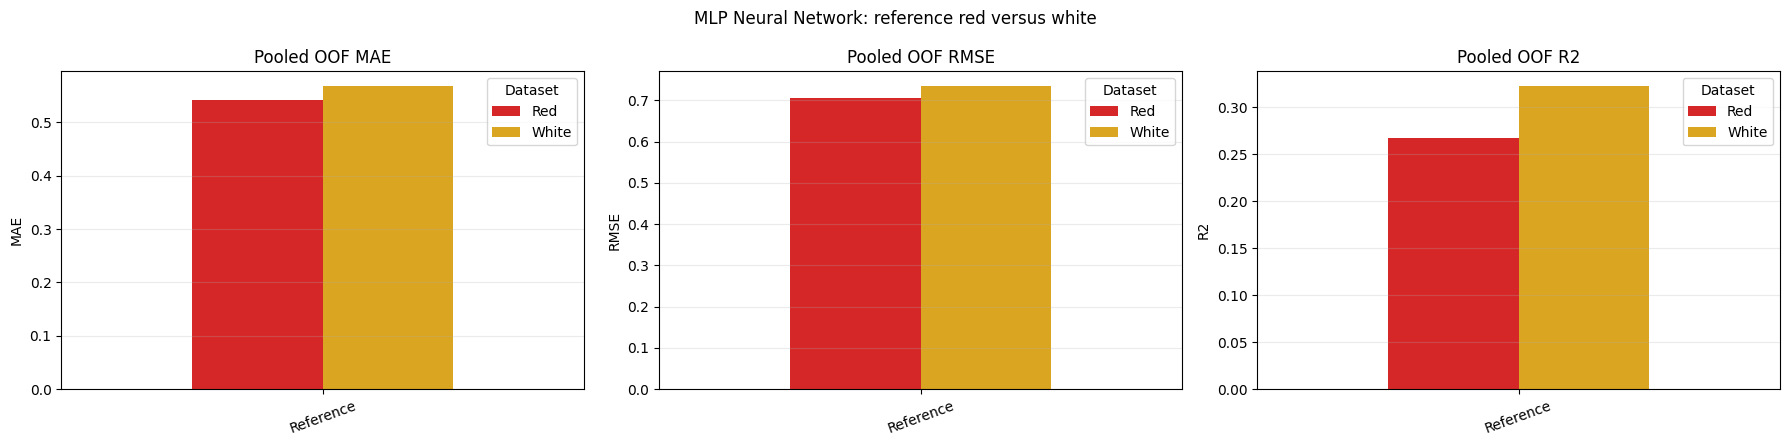

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5138,0.6783,0.3142,1.1329,1.3644,0.4188,0.7429
7,White,MLP,Reference,0.5797,0.7440,0.3022,1.2560,1.5194,0.4534,0.7003


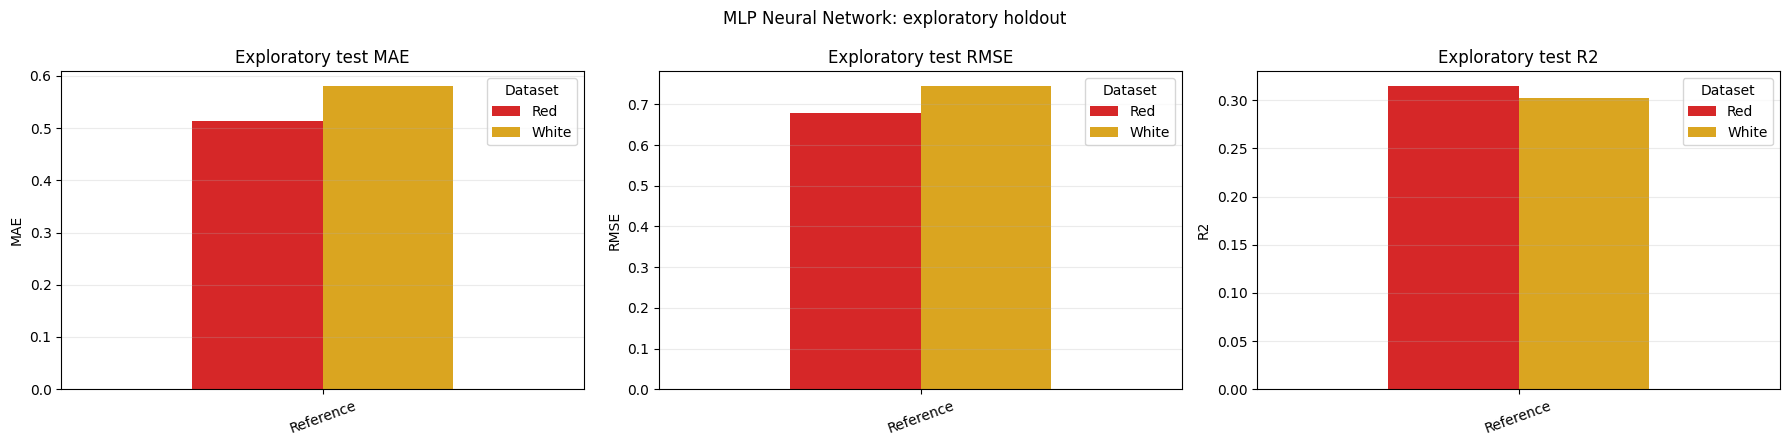

In [ ]:
comparison("MLP Neural Network: reference red versus white","MLP",["Reference"],metrics=("MAE","RMSE","R2"))
if RUN_HOLDOUT:
    comparison("MLP Neural Network: exploratory holdout","MLP",["Reference"],metrics=("MAE","RMSE","R2"),holdout=True)

## 4. Four-model reference comparison
Compare the four selected reference configurations before changing preprocessing. The objective is to establish starting behaviour, including rare-score error, rather than to declare an algorithm universally best.

**Observed reference results:** RF has the lowest overall OOF MAE among the four references (red 0.4905; white 0.5414). This ranking concerns the original training distribution and overall MAE, not every rare score or metric.


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,LR,Reference,raw,Original,Not applied,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188,0.0251
1,White,LR,Reference,raw,Original,Not applied,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567,0.0183
2,Red,RF,Reference,raw,Original,Not applied,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241,0.0224
3,White,RF,Reference,raw,Original,Not applied,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669,0.0144
4,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664,0.0266
5,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104
6,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534,0.0373
7,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113


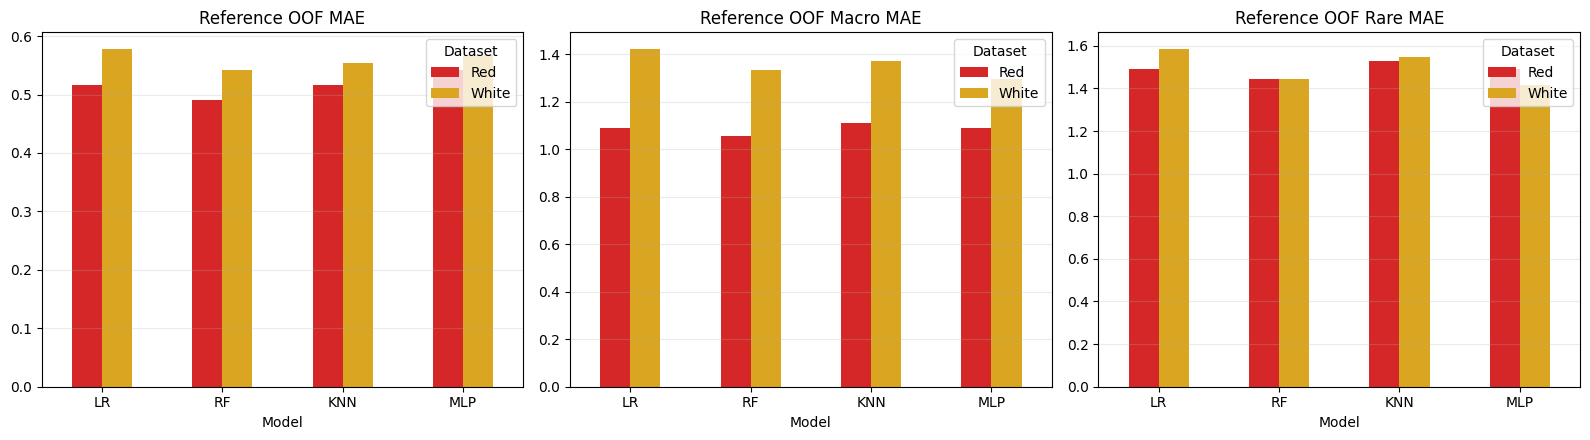

,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,MLP best epoch
0,Red,LR,Reference,raw,Original,Not applied,0.5066,0.6523,0.3657,1.1082,1.3838,0.3998,0.8027,NaN
1,White,LR,Reference,raw,Original,Not applied,0.5867,0.7608,0.2703,1.3764,1.6438,0.4448,0.7217,NaN
2,Red,RF,Reference,raw,Original,Not applied,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226,NaN
3,White,RF,Reference,raw,Original,Not applied,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633,NaN
4,Red,KNN,Reference,raw,Original,standard,0.5092,0.6651,0.3406,1.1350,1.4478,0.4062,0.7505,NaN
5,White,KNN,Reference,raw,Original,standard,0.5563,0.7215,0.3438,1.3372,1.5924,0.4303,0.6323,NaN
6,Red,MLP,Reference,raw,Original,standard,0.5138,0.6783,0.3142,1.1329,1.3644,0.4188,0.7429,135.0
7,White,MLP,Reference,raw,Original,standard,0.5797,0.7440,0.3022,1.2560,1.5194,0.4534,0.7003,54.0


In [ ]:
reference_cv = pd.DataFrame(ALL_CV_ROWS).query("Variant == 'Reference'")
display(reference_cv.round(4))
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for ax,metric in zip(axes,["MAE","Macro MAE","Rare MAE"]):
    reference_cv.pivot(index="Model",columns="Dataset",values=metric).reindex(MODEL_NAMES).plot.bar(
        ax=ax,color=["tab:red","goldenrod"],rot=0)
    ax.set_title(f"Reference OOF {metric}");ax.grid(axis="y",alpha=.25)
plt.tight_layout();plt.savefig(OUTPUT/"four_model_reference.png",dpi=200);plt.show();plt.close("all")
if RUN_HOLDOUT:
    display(pd.DataFrame(ALL_TEST_ROWS).query("Variant == 'Reference'").round(4))

## 5. Scaling experiments
Investigate KNN and MLP separately with no scaling, StandardScaler and RobustScaler. Only the scaling choice changes; representation and training distribution remain fixed. RobustScaler uses the median and interquartile range; it does not remove outliers or solve target imbalance. LR and RF do not require this scaling comparison.

**Observed scaling results:** KNN without scaling has higher overall OOF MAE for both datasets. For MLP the pattern is mixed: no scaling has lower overall MAE on red (0.5324 versus 0.5421), while robust scaling is slightly lower on white (0.5640 versus 0.5669). These single-seed differences do not establish statistical significance.


### 5.1 KNN — sensitivity to scaling
#### Red wine — calculations

In [ ]:
red_knn_scaling = [red_knn_reference]
for scaler in ["none","robust"]:
    red_knn_scaling.append(condition("Red","KNN",variant=f"Scale {scaler}",scaling=scaler))
display(pd.DataFrame(red_knn_scaling).round(4))

Completed: Red | KNN | Scale none
Completed: Red | KNN | Scale robust


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664,0.0266
1,Red,KNN,Scale none,raw,Original,none,0.5693,0.7354,0.2040,1.2985,1.7324,0.4170,1.0241,0.0409
2,Red,KNN,Scale robust,raw,Original,robust,0.5174,0.6711,0.3372,1.1360,1.5404,0.4033,0.7856,0.0278


#### White wine — calculations

In [ ]:
white_knn_scaling = [white_knn_reference]
for scaler in ["none","robust"]:
    white_knn_scaling.append(condition("White","KNN",variant=f"Scale {scaler}",scaling=scaler))
display(pd.DataFrame(white_knn_scaling).round(4))

Completed: White | KNN | Scale none
Completed: White | KNN | Scale robust


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104
1,White,KNN,Scale none,raw,Original,none,0.6285,0.7989,0.1952,1.4913,1.7153,0.4640,0.8489,0.0127
2,White,KNN,Scale robust,raw,Original,robust,0.5529,0.7216,0.3434,1.3759,1.5571,0.4213,0.6690,0.0120


#### Combined results
Reference means StandardScaler. Lower OOF errors indicate better observed performance at these fixed settings; do not assume that robust scaling must win.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664
5,White,KNN,Reference,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651
8,Red,KNN,Scale none,0.5693,0.7354,0.2040,1.2985,1.7324,0.4170,1.0241
9,Red,KNN,Scale robust,0.5174,0.6711,0.3372,1.1360,1.5404,0.4033,0.7856
10,White,KNN,Scale none,0.6285,0.7989,0.1952,1.4913,1.7153,0.4640,0.8489
11,White,KNN,Scale robust,0.5529,0.7216,0.3434,1.3759,1.5571,0.4213,0.6690


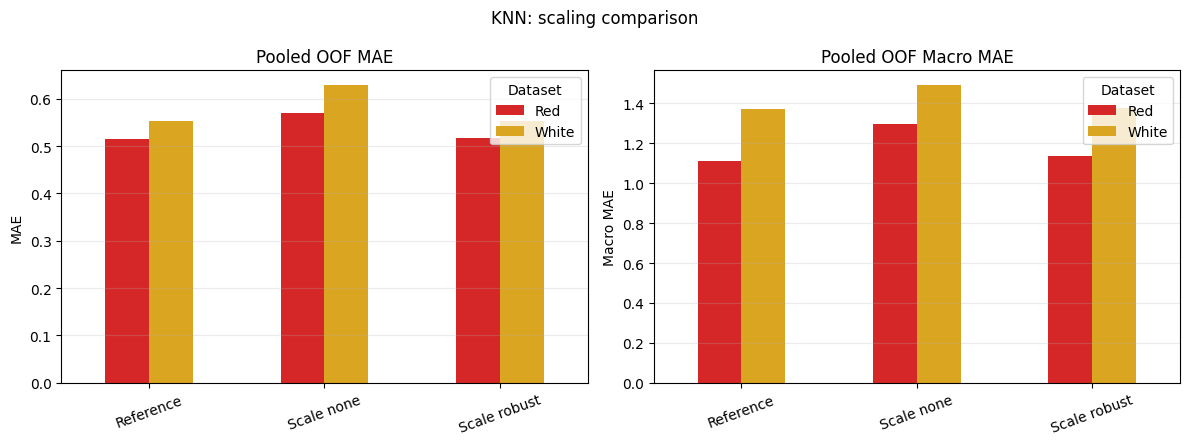

In [ ]:
comparison("KNN: scaling comparison","KNN",["Reference","Scale none","Scale robust"])

### 5.2 MLP Neural Network — sensitivity to scaling
#### Red wine — calculations

In [ ]:
red_mlp_scaling = [red_mlp_reference]
for scaler in ["none","robust"]:
    red_mlp_scaling.append(condition("Red","MLP",variant=f"Scale {scaler}",scaling=scaler))
display(pd.DataFrame(red_mlp_scaling).round(4))

Completed: Red | MLP | Scale none
Completed: Red | MLP | Scale robust


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534,0.0373
1,Red,MLP,Scale none,raw,Original,none,0.5324,0.6909,0.2976,1.1067,1.5404,0.4164,0.8207,0.0312
2,Red,MLP,Scale robust,raw,Original,robust,0.5553,0.7263,0.2236,1.1102,1.4724,0.4610,0.7427,0.0492


#### White wine — calculations

In [ ]:
white_mlp_scaling = [white_mlp_reference]
for scaler in ["none","robust"]:
    white_mlp_scaling.append(condition("White","MLP",variant=f"Scale {scaler}",scaling=scaler))
display(pd.DataFrame(white_mlp_scaling).round(4))

Completed: White | MLP | Scale none
Completed: White | MLP | Scale robust


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113
1,White,MLP,Scale none,raw,Original,none,0.5885,0.7563,0.2788,1.3653,1.5246,0.4563,0.7374,0.0207
2,White,MLP,Scale robust,raw,Original,robust,0.5640,0.7319,0.3245,1.3338,1.4419,0.4425,0.6930,0.0107


#### Combined results
Reference means StandardScaler. Lower OOF errors indicate better observed performance at these fixed settings; do not assume that robust scaling must win.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534
7,White,MLP,Reference,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803
12,Red,MLP,Scale none,0.5324,0.6909,0.2976,1.1067,1.5404,0.4164,0.8207
13,Red,MLP,Scale robust,0.5553,0.7263,0.2236,1.1102,1.4724,0.4610,0.7427
14,White,MLP,Scale none,0.5885,0.7563,0.2788,1.3653,1.5246,0.4563,0.7374
15,White,MLP,Scale robust,0.5640,0.7319,0.3245,1.3338,1.4419,0.4425,0.6930


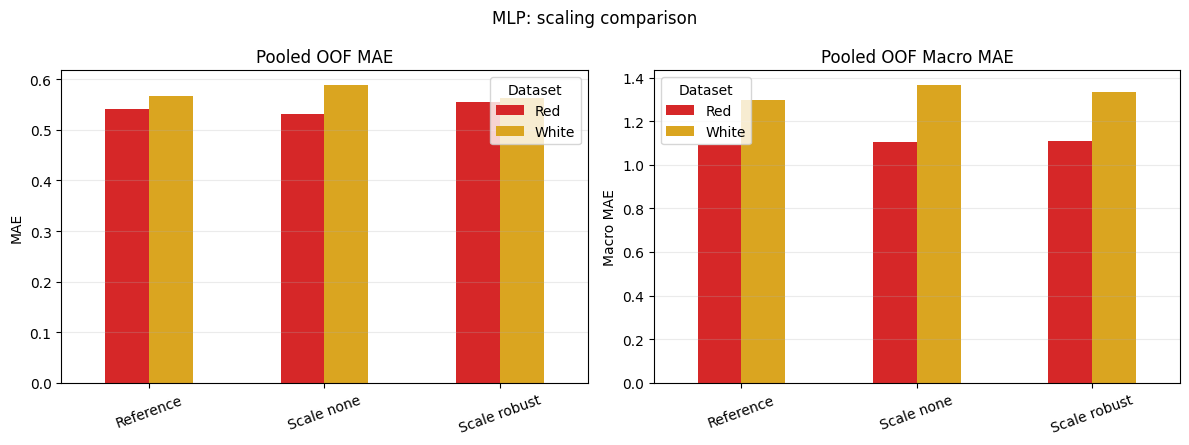

In [ ]:
comparison("MLP: scaling comparison","MLP",["Reference","Scale none","Scale robust"])

## 6. Log transformation of skewed chemical inputs
Within each fitting partition select columns with skewness >1, then use log for strictly positive columns or log1p when zeros occur. The target is not transformed. Validation/test log inputs are floored at the predeclared 1e-6 if an unseen zero occurs in a log column.

Hypothesis: changing feature spacing may affect linear fitting, KNN neighbourhoods and MLP optimisation. Tree splits are relatively insensitive to monotonic transformations, but exact RF predictions need not be identical. A reduction in skewness is not proof of improved prediction.

**Observed log results:** log inputs give small overall OOF MAE reductions for LR, KNN and MLP in both datasets. RF changes very little (red 0.4905 to 0.4907; white 0.5414 to 0.5412). Improvements are not uniform across individual scores.


### 6.1 Descriptive training-only skewness comparison
The table below describes full training inputs; CV still learns transform choices independently inside each fitting partition.

,Dataset,Feature,Transform,Before skewness,After skewness
0,Red,residual sugar,log,4.488,1.740
1,Red,chlorides,log,5.873,1.753
2,Red,free sulfur dioxide,log,1.234,-0.203
3,Red,total sulfur dioxide,log,1.590,-0.072
4,Red,sulphates,log,2.499,0.973
5,White,volatile acidity,log,1.678,0.207
6,White,citric acid,log1p,1.329,0.567
7,White,chlorides,log,5.101,1.276
8,White,free sulfur dioxide,log,1.785,-0.890


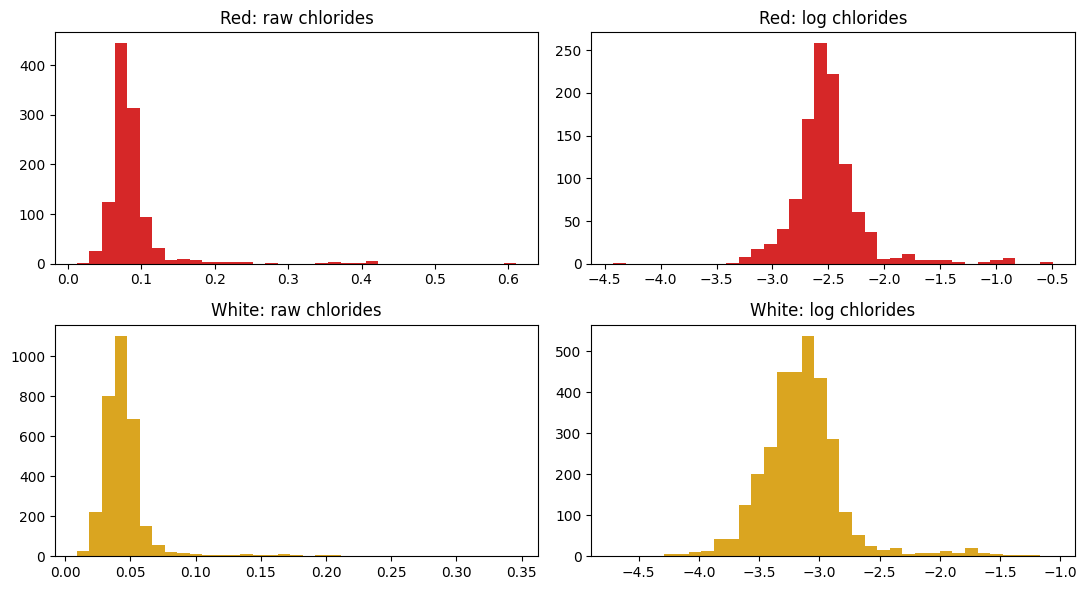

In [ ]:
skew_tables=[]
for wine,(a,b,c,d) in DATASETS.items():
    diagnostic=WineRegressor(model_name="LR",wine=wine,representation="log").fit(a,c)
    transformed=pd.DataFrame(diagnostic._represent(a),columns=diagnostic.columns_,index=a.index)
    for feature,method in diagnostic.log_methods_.items():
        skew_tables.append({"Dataset":wine,"Feature":feature,"Transform":method,
            "Before skewness":a[feature].skew(),"After skewness":transformed[feature].skew()})
skew_table=pd.DataFrame(skew_tables);display(skew_table.round(3))
skew_table.to_csv(OUTPUT/"descriptive_training_skewness.csv",index=False)
fig,axes=plt.subplots(2,2,figsize=(11,6))
for row,(wine,(a,b,c,d)) in enumerate(DATASETS.items()):
    axes[row,0].hist(a["chlorides"],bins=35,color="tab:red" if wine=="Red" else "goldenrod")
    axes[row,1].hist(np.log(a["chlorides"].clip(lower=1e-6)),bins=35,color="tab:red" if wine=="Red" else "goldenrod")
    axes[row,0].set_title(f"{wine}: raw chlorides");axes[row,1].set_title(f"{wine}: log chlorides")
plt.tight_layout();plt.savefig(OUTPUT/"log_distribution_example.png",dpi=200);plt.show();plt.close("all")

### 6.2 Linear Regression — raw versus log inputs
#### Red wine — calculations

In [ ]:
red_lr_log = condition("Red","LR",variant="Log",representation="log")
display(pd.DataFrame([red_lr_reference,red_lr_log]).round(4))

Completed: Red | LR | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,LR,Reference,raw,Original,Not applied,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188,0.0251
1,Red,LR,Log,log,Original,Not applied,0.5127,0.6630,0.3531,1.0795,1.4814,0.3996,0.8003,0.0241


#### White wine — calculations

In [ ]:
white_lr_log = condition("White","LR",variant="Log",representation="log")
display(pd.DataFrame([white_lr_reference,white_lr_log]).round(4))

Completed: White | LR | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,LR,Reference,raw,Original,Not applied,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567,0.0183
1,White,LR,Log,log,Original,Not applied,0.5721,0.7365,0.3160,1.3861,1.5426,0.4327,0.7366,0.0143


#### Combined results
Compare original and transformed inputs while holding model settings and training distribution fixed. Conclusions should follow the generated differences, not the hypothesis alone.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188
1,White,LR,Reference,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567
16,Red,LR,Log,0.5127,0.6630,0.3531,1.0795,1.4814,0.3996,0.8003
17,White,LR,Log,0.5721,0.7365,0.3160,1.3861,1.5426,0.4327,0.7366


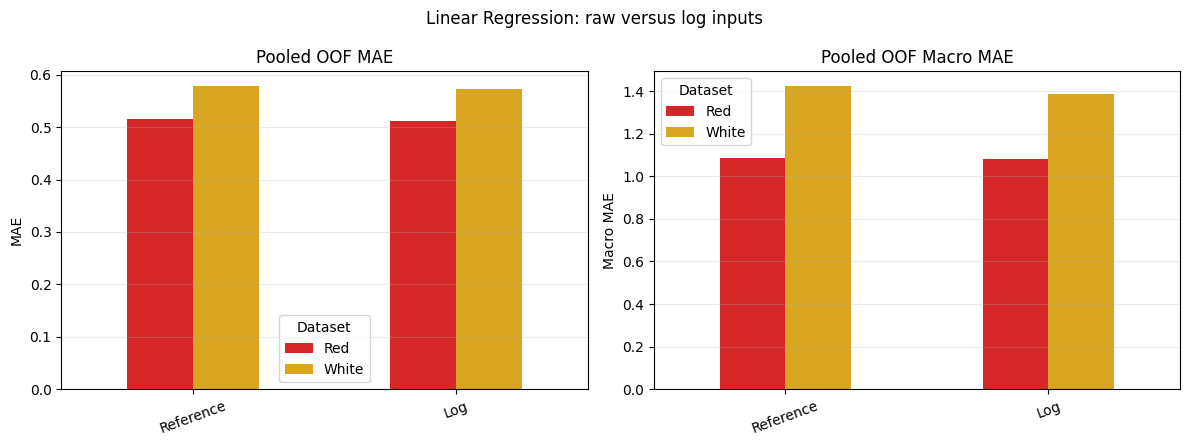

In [ ]:
comparison("Linear Regression: raw versus log inputs","LR",["Reference","Log"])

### 6.3 Random Forest — raw versus log inputs
#### Red wine — calculations

In [ ]:
red_rf_log = condition("Red","RF",variant="Log",representation="log")
display(pd.DataFrame([red_rf_reference,red_rf_log]).round(4))

Completed: Red | RF | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,RF,Reference,raw,Original,Not applied,0.4905,0.6408,0.3956,1.056,1.4454,0.3865,0.7241,0.0224
1,Red,RF,Log,log,Original,Not applied,0.4907,0.6410,0.3952,1.056,1.4457,0.3865,0.7256,0.0225


#### White wine — calculations

In [ ]:
white_rf_log = condition("White","RF",variant="Log",representation="log")
display(pd.DataFrame([white_rf_reference,white_rf_log]).round(4))

Completed: White | RF | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,RF,Reference,raw,Original,Not applied,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669,0.0144
1,White,RF,Log,log,Original,Not applied,0.5412,0.7040,0.3751,1.3323,1.4412,0.4183,0.6663,0.0145


#### Combined results
Compare original and transformed inputs while holding model settings and training distribution fixed. Conclusions should follow the generated differences, not the hypothesis alone.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241
3,White,RF,Reference,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669
18,Red,RF,Log,0.4907,0.6410,0.3952,1.0560,1.4457,0.3865,0.7256
19,White,RF,Log,0.5412,0.7040,0.3751,1.3323,1.4412,0.4183,0.6663


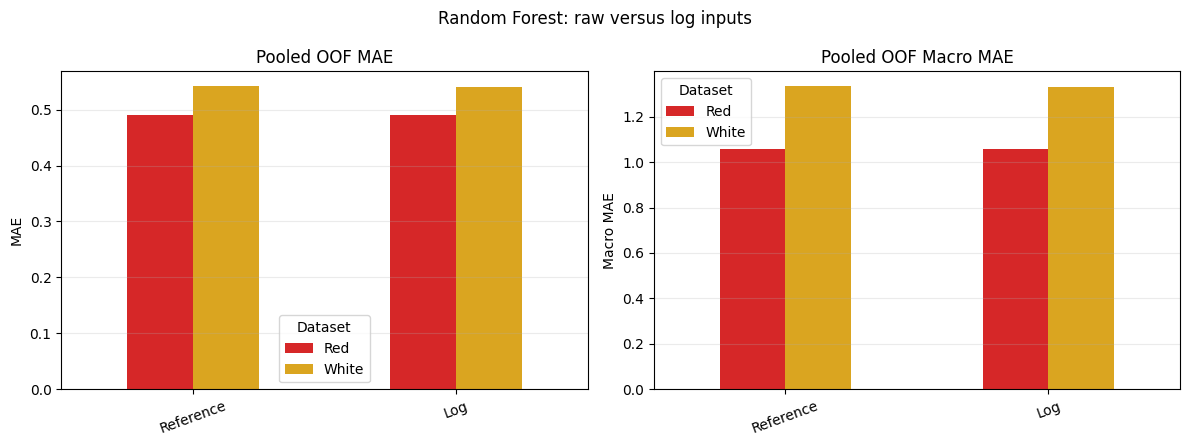

In [ ]:
comparison("Random Forest: raw versus log inputs","RF",["Reference","Log"])

### 6.4 KNN — raw versus log inputs
#### Red wine — calculations

In [ ]:
red_knn_log = condition("Red","KNN",variant="Log",representation="log")
display(pd.DataFrame([red_knn_reference,red_knn_log]).round(4))

Completed: Red | KNN | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.528,0.4051,0.7664,0.0266
1,Red,KNN,Log,log,Original,standard,0.5131,0.6632,0.3528,1.1093,1.530,0.4052,0.7434,0.0307


#### White wine — calculations

In [ ]:
white_knn_log = condition("White","KNN",variant="Log",representation="log")
display(pd.DataFrame([white_knn_reference,white_knn_log]).round(4))

Completed: White | KNN | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104
1,White,KNN,Log,log,Original,standard,0.5518,0.7191,0.3480,1.3664,1.5428,0.4243,0.6556,0.0101


#### Combined results
Compare original and transformed inputs while holding model settings and training distribution fixed. Conclusions should follow the generated differences, not the hypothesis alone.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664
5,White,KNN,Reference,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651
20,Red,KNN,Log,0.5131,0.6632,0.3528,1.1093,1.5300,0.4052,0.7434
21,White,KNN,Log,0.5518,0.7191,0.3480,1.3664,1.5428,0.4243,0.6556


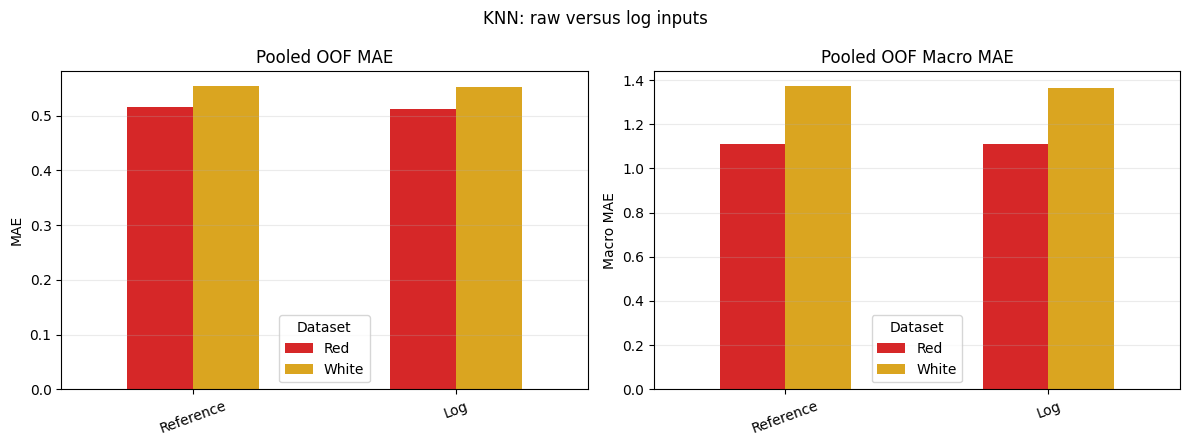

In [ ]:
comparison("KNN: raw versus log inputs","KNN",["Reference","Log"])

### 6.5 MLP Neural Network — raw versus log inputs
#### Red wine — calculations

In [ ]:
red_mlp_log = condition("Red","MLP",variant="Log",representation="log")
display(pd.DataFrame([red_mlp_reference,red_mlp_log]).round(4))

Completed: Red | MLP | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534,0.0373
1,Red,MLP,Log,log,Original,standard,0.5403,0.7001,0.2786,1.0865,1.4783,0.4405,0.7542,0.0286


#### White wine — calculations

In [ ]:
white_mlp_log = condition("White","MLP",variant="Log",representation="log")
display(pd.DataFrame([white_mlp_reference,white_mlp_log]).round(4))

Completed: White | MLP | Log


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113
1,White,MLP,Log,log,Original,standard,0.5614,0.7251,0.3371,1.2757,1.3822,0.4494,0.6749,0.0083


#### Combined results
Compare original and transformed inputs while holding model settings and training distribution fixed. Conclusions should follow the generated differences, not the hypothesis alone.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534
7,White,MLP,Reference,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803
22,Red,MLP,Log,0.5403,0.7001,0.2786,1.0865,1.4783,0.4405,0.7542
23,White,MLP,Log,0.5614,0.7251,0.3371,1.2757,1.3822,0.4494,0.6749


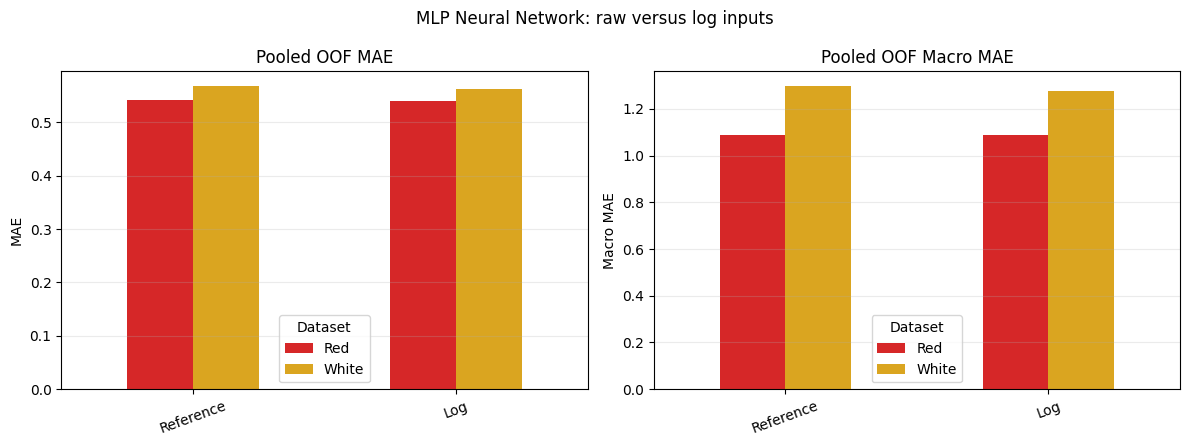

In [ ]:
comparison("MLP Neural Network: raw versus log inputs","MLP",["Reference","Log"])

## 7. Feature-subset experiments
Compare 3, 5, 8 and all 11 inputs. SelectKBest(f_regression) learns its ranking inside each fitting partition, keeping outer validation targets out of selection. RF/LR/KNN use the complete outer training partition for this; MLP selection uses its smaller fitting partition so its inner stopping validation also remains excluded.

For this reason MLP's selected features may differ from other models; this is documented rather than claiming identical subsets. Within a given fitting partition, top-k subsets follow the same F-score ranking. The experiment evaluates this selection procedure, not the claim that a single fixed list is sufficient for all wines.

**Observed feature-count results:** the effect depends on model and dataset. Red MLP with three selected inputs has lower overall OOF MAE than its 11-input reference (0.5098 versus 0.5421). White three-feature configurations have higher overall MAE for all four models. These results evaluate fold-fitted feature selection; they do not prove one fixed three-feature list is sufficient.


### 7.1 Linear Regression — feature count
#### Red wine — calculations

In [ ]:
red_lr_features = [red_lr_reference]
for k in [3,5,8]:
    red_lr_features.append(condition("Red","LR",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(red_lr_features).round(4))

Completed: Red | LR | Top 3
Completed: Red | LR | Top 5
Completed: Red | LR | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,LR,Reference,raw,Original,Not applied,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188,0.0251
1,Red,LR,Top 3,top3,Original,Not applied,0.5225,0.6715,0.3365,1.0939,1.5019,0.4037,0.8428,0.0257
2,Red,LR,Top 5,top5,Original,Not applied,0.5219,0.6732,0.3330,1.1020,1.5144,0.4025,0.8398,0.0215
3,Red,LR,Top 8,top8,Original,Not applied,0.5155,0.6673,0.3447,1.0971,1.5117,0.3993,0.8107,0.0252


#### White wine — calculations

In [ ]:
white_lr_features = [white_lr_reference]
for k in [3,5,8]:
    white_lr_features.append(condition("White","LR",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(white_lr_features).round(4))

Completed: White | LR | Top 3
Completed: White | LR | Top 5
Completed: White | LR | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,LR,Reference,raw,Original,Not applied,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567,0.0183
1,White,LR,Top 3,top3,Original,Not applied,0.6149,0.7862,0.2207,1.5107,1.7798,0.4437,0.8292,0.0255
2,White,LR,Top 5,top5,Original,Not applied,0.5933,0.7633,0.2653,1.4646,1.6710,0.4333,0.7986,0.0237
3,White,LR,Top 8,top8,Original,Not applied,0.5835,0.7510,0.2888,1.4279,1.6028,0.4329,0.7741,0.0198


#### Combined results
Reference uses all 11 inputs. Describe the actual error-versus-feature-count trade-off. Small differences do not establish equivalence or prove that omitted measurements have no value.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188
1,White,LR,Reference,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567
24,Red,LR,Top 3,0.5225,0.6715,0.3365,1.0939,1.5019,0.4037,0.8428
25,Red,LR,Top 5,0.5219,0.6732,0.3330,1.1020,1.5144,0.4025,0.8398
26,Red,LR,Top 8,0.5155,0.6673,0.3447,1.0971,1.5117,0.3993,0.8107
27,White,LR,Top 3,0.6149,0.7862,0.2207,1.5107,1.7798,0.4437,0.8292
28,White,LR,Top 5,0.5933,0.7633,0.2653,1.4646,1.6710,0.4333,0.7986
29,White,LR,Top 8,0.5835,0.7510,0.2888,1.4279,1.6028,0.4329,0.7741


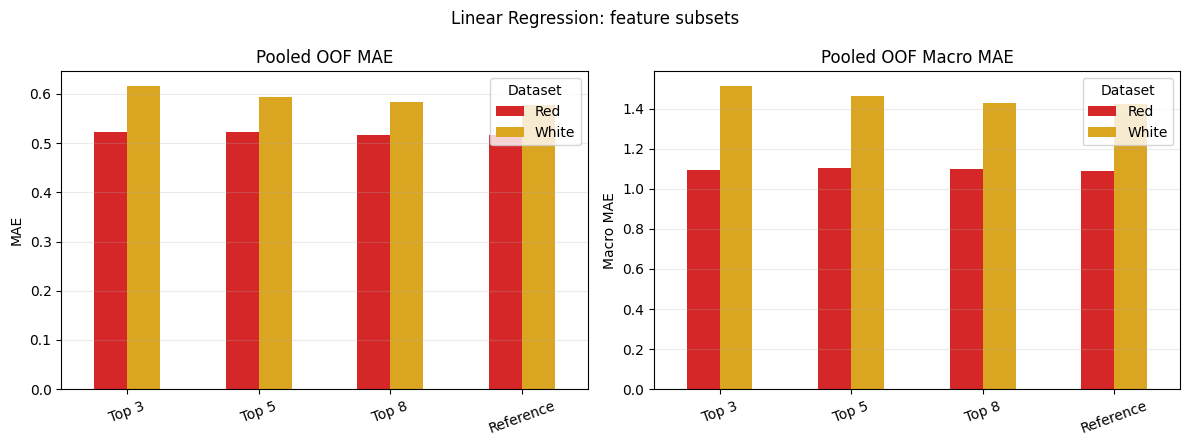

In [ ]:
comparison("Linear Regression: feature subsets","LR",["Top 3","Top 5","Top 8","Reference"])

### 7.2 Random Forest — feature count
#### Red wine — calculations

In [ ]:
red_rf_features = [red_rf_reference]
for k in [3,5,8]:
    red_rf_features.append(condition("Red","RF",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(red_rf_features).round(4))

Completed: Red | RF | Top 3
Completed: Red | RF | Top 5
Completed: Red | RF | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,RF,Reference,raw,Original,Not applied,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241,0.0224
1,Red,RF,Top 3,top3,Original,Not applied,0.5218,0.6781,0.3233,1.0865,1.4654,0.4187,0.7555,0.0176
2,Red,RF,Top 5,top5,Original,Not applied,0.5123,0.6668,0.3456,1.0790,1.4735,0.4077,0.7471,0.0184
3,Red,RF,Top 8,top8,Original,Not applied,0.4953,0.6474,0.3831,1.0538,1.4492,0.3911,0.7305,0.0210


#### White wine — calculations

In [ ]:
white_rf_features = [white_rf_reference]
for k in [3,5,8]:
    white_rf_features.append(condition("White","RF",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(white_rf_features).round(4))

Completed: White | RF | Top 3
Completed: White | RF | Top 5
Completed: White | RF | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,RF,Reference,raw,Original,Not applied,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669,0.0144
1,White,RF,Top 3,top3,Original,Not applied,0.6207,0.8075,0.1777,1.5177,1.7687,0.4646,0.7777,0.0207
2,White,RF,Top 5,top5,Original,Not applied,0.5758,0.7516,0.2878,1.3910,1.5860,0.4369,0.7207,0.0190
3,White,RF,Top 8,top8,Original,Not applied,0.5626,0.7326,0.3233,1.3855,1.5459,0.4298,0.6933,0.0186


#### Combined results
Reference uses all 11 inputs. Describe the actual error-versus-feature-count trade-off. Small differences do not establish equivalence or prove that omitted measurements have no value.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241
3,White,RF,Reference,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669
30,Red,RF,Top 3,0.5218,0.6781,0.3233,1.0865,1.4654,0.4187,0.7555
31,Red,RF,Top 5,0.5123,0.6668,0.3456,1.0790,1.4735,0.4077,0.7471
32,Red,RF,Top 8,0.4953,0.6474,0.3831,1.0538,1.4492,0.3911,0.7305
33,White,RF,Top 3,0.6207,0.8075,0.1777,1.5177,1.7687,0.4646,0.7777
34,White,RF,Top 5,0.5758,0.7516,0.2878,1.3910,1.5860,0.4369,0.7207
35,White,RF,Top 8,0.5626,0.7326,0.3233,1.3855,1.5459,0.4298,0.6933


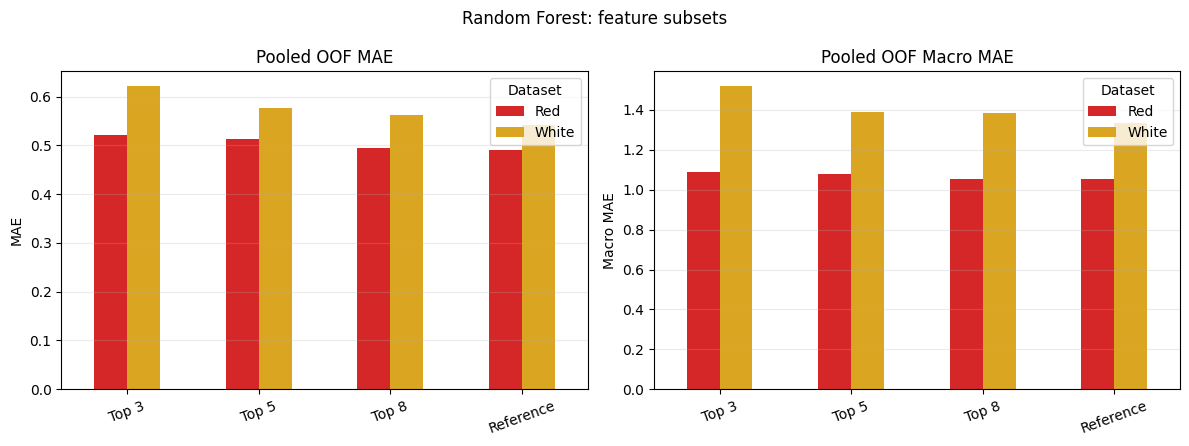

In [ ]:
comparison("Random Forest: feature subsets","RF",["Top 3","Top 5","Top 8","Reference"])

### 7.3 KNN — feature count
#### Red wine — calculations

In [ ]:
red_knn_features = [red_knn_reference]
for k in [3,5,8]:
    red_knn_features.append(condition("Red","KNN",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(red_knn_features).round(4))

Completed: Red | KNN | Top 3
Completed: Red | KNN | Top 5
Completed: Red | KNN | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664,0.0266
1,Red,KNN,Top 3,top3,Original,standard,0.5187,0.6743,0.3308,1.0944,1.4617,0.4147,0.7584,0.0210
2,Red,KNN,Top 5,top5,Original,standard,0.5126,0.6662,0.3469,1.1068,1.4903,0.4029,0.7732,0.0165
3,Red,KNN,Top 8,top8,Original,standard,0.5100,0.6621,0.3549,1.0959,1.5047,0.4017,0.7531,0.0195


#### White wine — calculations

In [ ]:
white_knn_features = [white_knn_reference]
for k in [3,5,8]:
    white_knn_features.append(condition("White","KNN",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(white_knn_features).round(4))

Completed: White | KNN | Top 3
Completed: White | KNN | Top 5
Completed: White | KNN | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104
1,White,KNN,Top 3,top3,Original,standard,0.6186,0.8070,0.1789,1.5026,1.7694,0.4614,0.7786,0.0222
2,White,KNN,Top 5,top5,Original,standard,0.5778,0.7552,0.2808,1.3860,1.6247,0.4377,0.7107,0.0183
3,White,KNN,Top 8,top8,Original,standard,0.5688,0.7436,0.3028,1.4086,1.6149,0.4300,0.6972,0.0142


#### Combined results
Reference uses all 11 inputs. Describe the actual error-versus-feature-count trade-off. Small differences do not establish equivalence or prove that omitted measurements have no value.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664
5,White,KNN,Reference,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651
36,Red,KNN,Top 3,0.5187,0.6743,0.3308,1.0944,1.4617,0.4147,0.7584
37,Red,KNN,Top 5,0.5126,0.6662,0.3469,1.1068,1.4903,0.4029,0.7732
38,Red,KNN,Top 8,0.5100,0.6621,0.3549,1.0959,1.5047,0.4017,0.7531
39,White,KNN,Top 3,0.6186,0.8070,0.1789,1.5026,1.7694,0.4614,0.7786
40,White,KNN,Top 5,0.5778,0.7552,0.2808,1.3860,1.6247,0.4377,0.7107
41,White,KNN,Top 8,0.5688,0.7436,0.3028,1.4086,1.6149,0.4300,0.6972


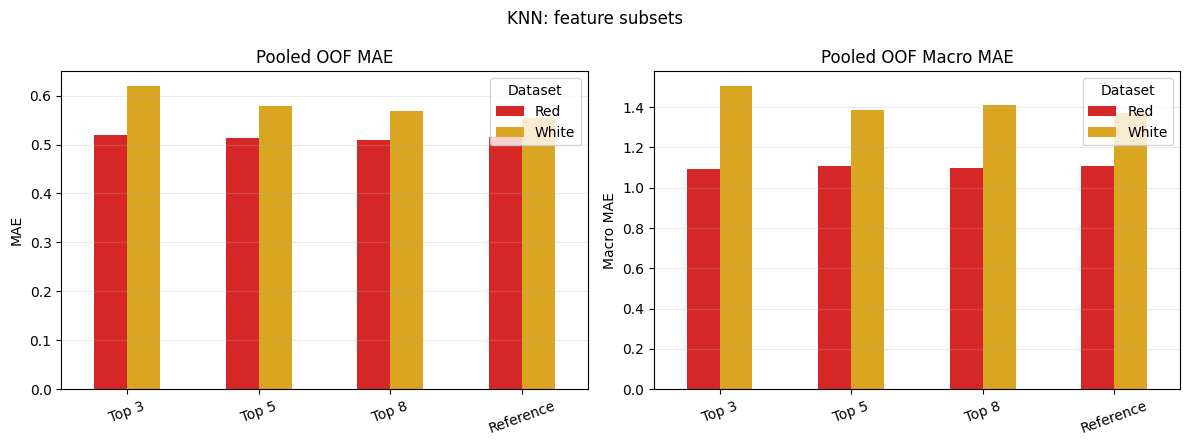

In [ ]:
comparison("KNN: feature subsets","KNN",["Top 3","Top 5","Top 8","Reference"])

### 7.4 MLP Neural Network — feature count
#### Red wine — calculations

In [ ]:
red_mlp_features = [red_mlp_reference]
for k in [3,5,8]:
    red_mlp_features.append(condition("Red","MLP",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(red_mlp_features).round(4))

Completed: Red | MLP | Top 3
Completed: Red | MLP | Top 5
Completed: Red | MLP | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534,0.0373
1,Red,MLP,Top 3,top3,Original,standard,0.5098,0.6647,0.3498,1.0407,1.3950,0.4055,0.7787,0.0166
2,Red,MLP,Top 5,top5,Original,standard,0.5248,0.6777,0.3241,1.0889,1.4626,0.4199,0.7733,0.0229
3,Red,MLP,Top 8,top8,Original,standard,0.5236,0.6831,0.3132,1.0917,1.4516,0.4232,0.7460,0.0506


#### White wine — calculations

In [ ]:
white_mlp_features = [white_mlp_reference]
for k in [3,5,8]:
    white_mlp_features.append(condition("White","MLP",variant=f"Top {k}",representation=f"top{k}"))
display(pd.DataFrame(white_mlp_features).round(4))

Completed: White | MLP | Top 3
Completed: White | MLP | Top 5
Completed: White | MLP | Top 8


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113
1,White,MLP,Top 3,top3,Original,standard,0.6039,0.7774,0.2379,1.4828,1.7211,0.4422,0.7986,0.0304
2,White,MLP,Top 5,top5,Original,standard,0.5812,0.7472,0.2961,1.3660,1.5626,0.4428,0.7367,0.0179
3,White,MLP,Top 8,top8,Original,standard,0.5709,0.7363,0.3164,1.3485,1.4932,0.4451,0.6984,0.0145


#### Combined results
Reference uses all 11 inputs. Describe the actual error-versus-feature-count trade-off. Small differences do not establish equivalence or prove that omitted measurements have no value.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534
7,White,MLP,Reference,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803
42,Red,MLP,Top 3,0.5098,0.6647,0.3498,1.0407,1.3950,0.4055,0.7787
43,Red,MLP,Top 5,0.5248,0.6777,0.3241,1.0889,1.4626,0.4199,0.7733
44,Red,MLP,Top 8,0.5236,0.6831,0.3132,1.0917,1.4516,0.4232,0.7460
45,White,MLP,Top 3,0.6039,0.7774,0.2379,1.4828,1.7211,0.4422,0.7986
46,White,MLP,Top 5,0.5812,0.7472,0.2961,1.3660,1.5626,0.4428,0.7367
47,White,MLP,Top 8,0.5709,0.7363,0.3164,1.3485,1.4932,0.4451,0.6984


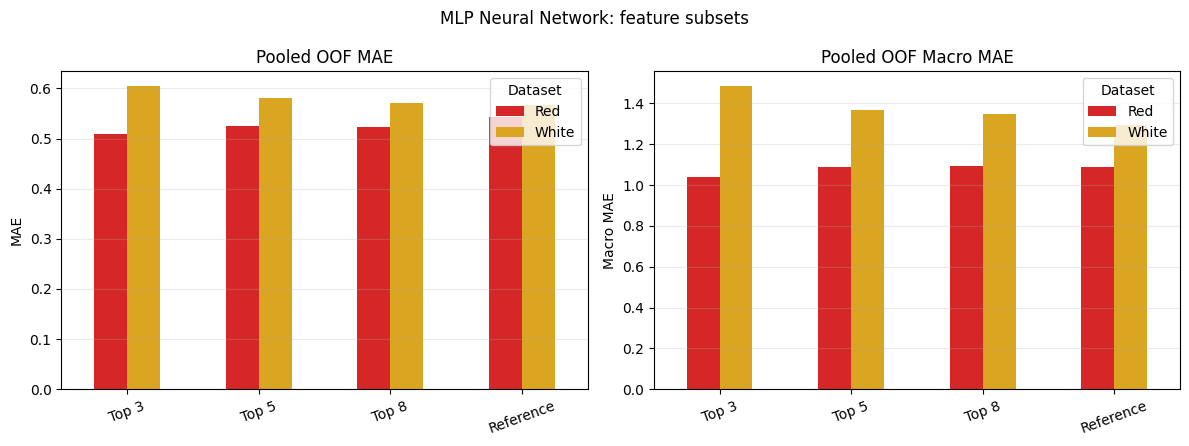

In [ ]:
comparison("MLP Neural Network: feature subsets","MLP",["Top 3","Top 5","Top 8","Reference"])

## 8. Rare-score handling: weighting and oversampling
The main question is whether emphasis on uncommon scores reduces their errors, and what happens to common-score and overall accuracy. Original validation/test distributions remain unchanged. No new information is created by duplicating training records.

“Oversample” uses a minimum count equal to 10% of the original fitting-partition size. “Weight soft/full” uses normalised inverse score-frequency weights with power 0.5/1.0. The frequency-based treatments can affect score 7, although the predeclared rare-error group is ≤4 or ≥8. Inspect every score, including 7, rather than only the pooled rare group.

**Observed imbalance results:** the tested treatments reduce pooled rare MAE but increase overall OOF MAE relative to each reference. For white MLP, oversampling reduces rare MAE (1.4142 to 1.3578) while worsening macro MAE (1.2959 to 1.3278); quality-3 error worsens. Show per-score counts and actual duplication factors instead of claiming every rare score improves.


### 8.1 Linear Regression — rare-score treatments
Compare original training, oversampling, soft weighting and full weighting at fixed model settings.

#### Red wine — calculations

In [ ]:
red_lr_rare = [red_lr_reference]
for treatment in ['Oversample', 'Weight soft', 'Weight full']:
    red_lr_rare.append(condition("Red","LR",variant=treatment,treatment=treatment))
display(pd.DataFrame(red_lr_rare).round(4))

Completed: Red | LR | Oversample
Completed: Red | LR | Weight soft
Completed: Red | LR | Weight full


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,LR,Reference,raw,Original,Not applied,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188,0.0251
1,Red,LR,Oversample,raw,Oversample,Not applied,0.5929,0.7566,0.1576,0.8785,1.1117,0.5431,0.6756,0.0247
2,Red,LR,Weight soft,raw,Weight soft,Not applied,0.5657,0.7224,0.2319,0.9090,1.1983,0.5063,0.6573,0.0177
3,Red,LR,Weight full,raw,Weight full,Not applied,0.7229,0.9223,-0.2517,0.8325,0.9296,0.7146,0.6793,0.0321


#### White wine — calculations

In [ ]:
white_lr_rare = [white_lr_reference]
for treatment in ['Oversample', 'Weight soft', 'Weight full']:
    white_lr_rare.append(condition("White","LR",variant=treatment,treatment=treatment))
display(pd.DataFrame(white_lr_rare).round(4))

Completed: White | LR | Oversample
Completed: White | LR | Weight soft
Completed: White | LR | Weight full


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,LR,Reference,raw,Original,Not applied,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567,0.0183
1,White,LR,Oversample,raw,Oversample,Not applied,0.6396,0.8280,0.1355,1.4025,1.3994,0.5498,0.6853,0.0232
2,White,LR,Weight soft,raw,Weight soft,Not applied,0.6017,0.7785,0.2359,1.3534,1.4355,0.4991,0.6695,0.0188
3,White,LR,Weight full,raw,Weight full,Not applied,0.7552,0.9685,-0.1827,1.3964,1.3046,0.7046,0.7268,0.0344


#### Combined results
Read overall, macro and rare-score MAE together. A lower rare-score error can come at a cost to typical wines; report both sides of the trade-off.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5160,0.6674,0.3445,1.0880,1.4906,0.4002,0.8188
1,White,LR,Reference,0.5776,0.7460,0.2983,1.4217,1.5839,0.4311,0.7567
48,Red,LR,Oversample,0.5929,0.7566,0.1576,0.8785,1.1117,0.5431,0.6756
49,Red,LR,Weight soft,0.5657,0.7224,0.2319,0.9090,1.1983,0.5063,0.6573
50,Red,LR,Weight full,0.7229,0.9223,-0.2517,0.8325,0.9296,0.7146,0.6793
51,White,LR,Oversample,0.6396,0.8280,0.1355,1.4025,1.3994,0.5498,0.6853
52,White,LR,Weight soft,0.6017,0.7785,0.2359,1.3534,1.4355,0.4991,0.6695
53,White,LR,Weight full,0.7552,0.9685,-0.1827,1.3964,1.3046,0.7046,0.7268


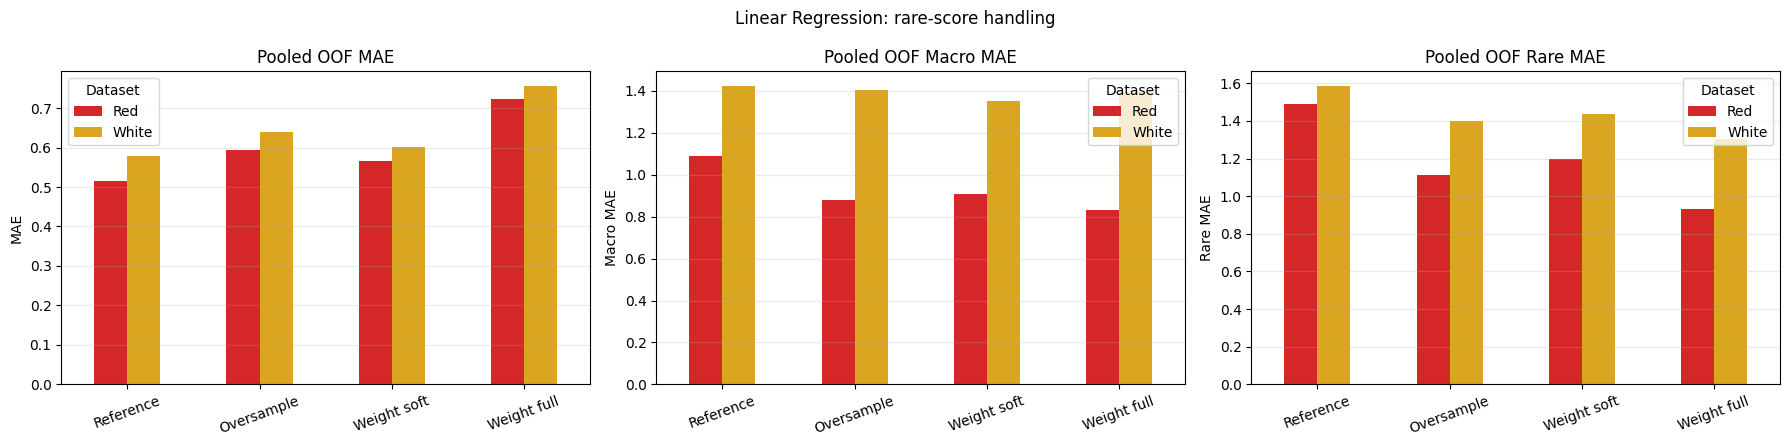

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
0,Red,LR,Reference,0.5066,0.6523,0.3657,1.1082,1.3838,0.3998,0.8027
1,White,LR,Reference,0.5867,0.7608,0.2703,1.3764,1.6438,0.4448,0.7217
48,Red,LR,Oversample,0.5565,0.7258,0.2148,0.9632,1.0581,0.5090,0.6341
49,Red,LR,Weight soft,0.5373,0.7022,0.2651,0.9718,1.1101,0.4835,0.6229
50,Red,LR,Weight full,0.6917,0.8915,-0.1847,0.9080,0.8933,0.6730,0.7203
51,White,LR,Oversample,0.6351,0.8644,0.0580,1.2313,1.4560,0.5551,0.6101
52,White,LR,Weight soft,0.6056,0.8010,0.1912,1.2734,1.5026,0.5076,0.6236
53,White,LR,Weight full,0.7483,1.0081,-0.2811,1.1779,1.3563,0.7082,0.6471


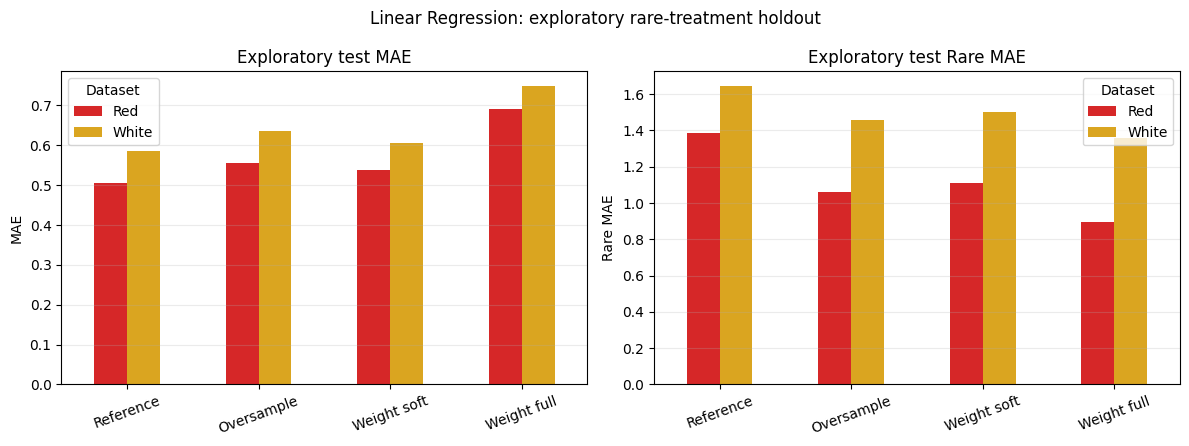

In [ ]:
comparison("Linear Regression: rare-score handling","LR",['Reference', 'Oversample', 'Weight soft', 'Weight full'],metrics=("MAE","Macro MAE","Rare MAE"))
if RUN_HOLDOUT:
    comparison("Linear Regression: exploratory rare-treatment holdout","LR",['Reference', 'Oversample', 'Weight soft', 'Weight full'],metrics=("MAE","Rare MAE"),holdout=True)

#### Errors at each actual quality score
These curves use pooled OOF predictions. Each x-axis label shows how many original validation observations support that score; duplicated fitting records do not increase evaluation counts.

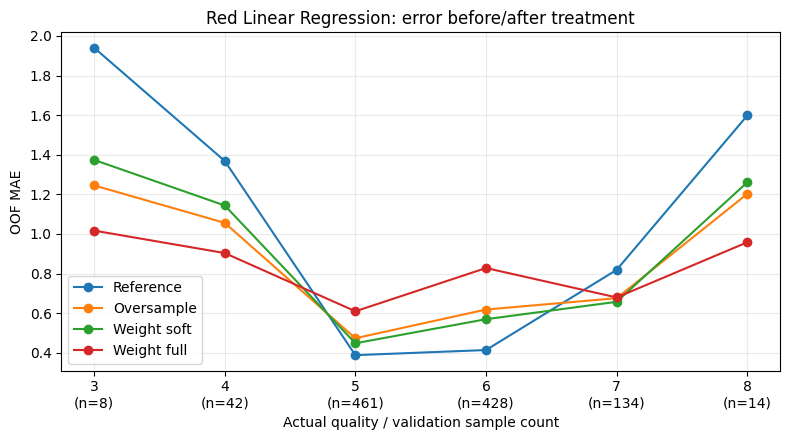

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,8,1.9408,4.9408,Red,LR,Reference
1,4.0,42,1.3689,5.3689,Red,LR,Reference
2,5.0,461,0.3878,5.3492,Red,LR,Reference
3,6.0,428,0.4136,5.7598,Red,LR,Reference
4,7.0,134,0.8188,6.1812,Red,LR,Reference
5,8.0,14,1.5984,6.4016,Red,LR,Reference
6,3.0,8,1.2453,4.1942,Red,LR,Oversample
7,4.0,42,1.0560,5.0560,Red,LR,Oversample
8,5.0,461,0.4732,5.1754,Red,LR,Oversample
9,6.0,428,0.6183,5.7560,Red,LR,Oversample


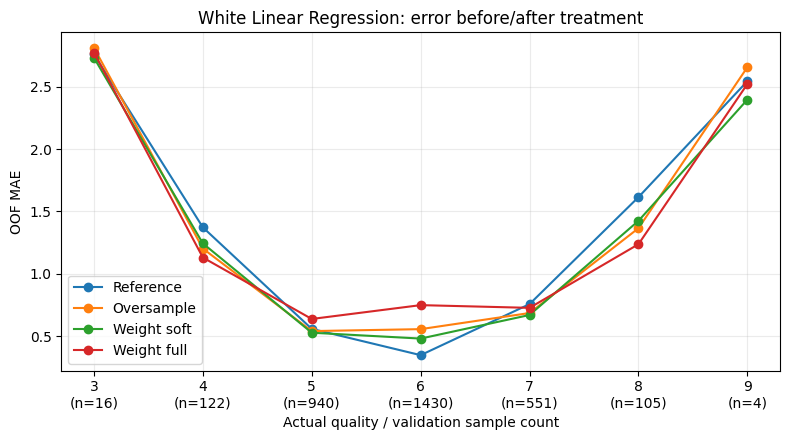

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,16,2.7592,5.7592,White,LR,Reference
1,4.0,122,1.3723,5.3709,White,LR,Reference
2,5.0,940,0.5581,5.5333,White,LR,Reference
3,6.0,1430,0.3475,5.9209,White,LR,Reference
4,7.0,551,0.7567,6.2459,White,LR,Reference
5,8.0,105,1.6141,6.3859,White,LR,Reference
6,9.0,4,2.5437,6.4563,White,LR,Reference
7,3.0,16,2.8126,5.8126,White,LR,Oversample
8,4.0,122,1.2023,5.1298,White,LR,Oversample
9,5.0,940,0.5404,5.3509,White,LR,Oversample


In [ ]:
score_comparison("Red","LR",['Reference', 'Oversample', 'Weight soft', 'Weight full'],"Red Linear Regression: error before/after treatment")
score_comparison("White","LR",['Reference', 'Oversample', 'Weight soft', 'Weight full'],"White Linear Regression: error before/after treatment")

### 8.2 Random Forest — rare-score treatments
Compare original training, oversampling, soft weighting and full weighting at fixed model settings.

#### Red wine — calculations

In [ ]:
red_rf_rare = [red_rf_reference]
for treatment in ['Oversample', 'Weight soft', 'Weight full']:
    red_rf_rare.append(condition("Red","RF",variant=treatment,treatment=treatment))
display(pd.DataFrame(red_rf_rare).round(4))

Completed: Red | RF | Oversample
Completed: Red | RF | Weight soft
Completed: Red | RF | Weight full


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,RF,Reference,raw,Original,Not applied,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241,0.0224
1,Red,RF,Oversample,raw,Oversample,Not applied,0.5112,0.6645,0.3501,0.9927,1.3424,0.4176,0.7354,0.0190
2,Red,RF,Weight soft,raw,Weight soft,Not applied,0.4972,0.6429,0.3918,0.9938,1.3510,0.4076,0.6841,0.0228
3,Red,RF,Weight full,raw,Weight full,Not applied,0.5017,0.6495,0.3792,0.9844,1.3343,0.4188,0.6538,0.0201


#### White wine — calculations

In [ ]:
white_rf_rare = [white_rf_reference]
for treatment in ['Oversample', 'Weight soft', 'Weight full']:
    white_rf_rare.append(condition("White","RF",variant=treatment,treatment=treatment))
display(pd.DataFrame(white_rf_rare).round(4))

Completed: White | RF | Oversample
Completed: White | RF | Weight soft
Completed: White | RF | Weight full


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,RF,Reference,raw,Original,Not applied,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669,0.0144
1,White,RF,Oversample,raw,Oversample,Not applied,0.5511,0.7182,0.3496,1.3122,1.3653,0.4422,0.6544,0.0089
2,White,RF,Weight soft,raw,Weight soft,Not applied,0.5457,0.7101,0.3643,1.3147,1.3934,0.4356,0.6392,0.0138
3,White,RF,Weight full,raw,Weight full,Not applied,0.5441,0.7094,0.3654,1.3058,1.3868,0.4388,0.6194,0.0119


#### Combined results
Read overall, macro and rare-score MAE together. A lower rare-score error can come at a cost to typical wines; report both sides of the trade-off.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4905,0.6408,0.3956,1.0560,1.4454,0.3865,0.7241
3,White,RF,Reference,0.5414,0.7042,0.3747,1.3330,1.4420,0.4183,0.6669
54,Red,RF,Oversample,0.5112,0.6645,0.3501,0.9927,1.3424,0.4176,0.7354
55,Red,RF,Weight soft,0.4972,0.6429,0.3918,0.9938,1.3510,0.4076,0.6841
56,Red,RF,Weight full,0.5017,0.6495,0.3792,0.9844,1.3343,0.4188,0.6538
57,White,RF,Oversample,0.5511,0.7182,0.3496,1.3122,1.3653,0.4422,0.6544
58,White,RF,Weight soft,0.5457,0.7101,0.3643,1.3147,1.3934,0.4356,0.6392
59,White,RF,Weight full,0.5441,0.7094,0.3654,1.3058,1.3868,0.4388,0.6194


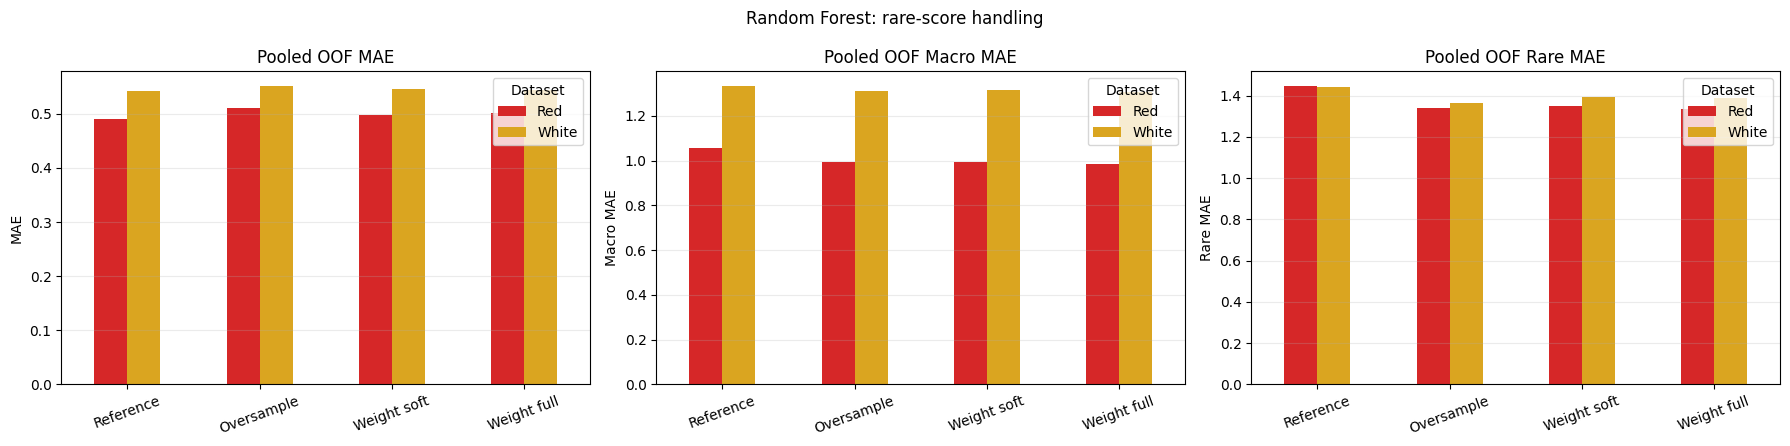

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
2,Red,RF,Reference,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226
3,White,RF,Reference,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633
54,Red,RF,Oversample,0.5016,0.6522,0.3659,1.0158,1.2084,0.4109,0.7717
55,Red,RF,Weight soft,0.4954,0.6413,0.3870,0.9926,1.1988,0.4111,0.7245
56,Red,RF,Weight full,0.5041,0.6455,0.3789,0.9867,1.1575,0.4271,0.7074
57,White,RF,Oversample,0.5373,0.6942,0.3925,1.2150,1.3282,0.4364,0.6153
58,White,RF,Weight soft,0.5416,0.6933,0.3941,1.2089,1.3382,0.4363,0.6364
59,White,RF,Weight full,0.5365,0.6885,0.4024,1.1637,1.3213,0.4395,0.6009


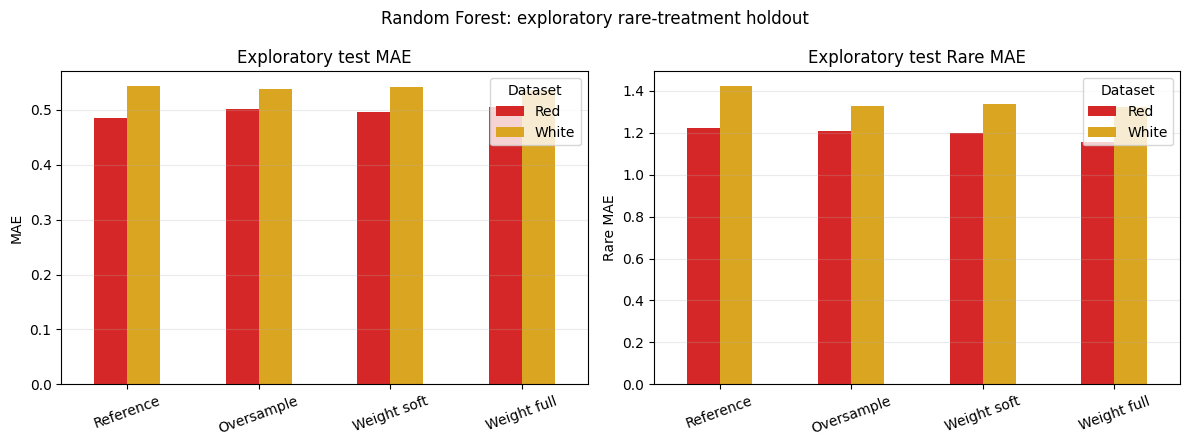

In [ ]:
comparison("Random Forest: rare-score handling","RF",['Reference', 'Oversample', 'Weight soft', 'Weight full'],metrics=("MAE","Macro MAE","Rare MAE"))
if RUN_HOLDOUT:
    comparison("Random Forest: exploratory rare-treatment holdout","RF",['Reference', 'Oversample', 'Weight soft', 'Weight full'],metrics=("MAE","Rare MAE"),holdout=True)

#### Errors at each actual quality score
These curves use pooled OOF predictions. Each x-axis label shows how many original validation observations support that score; duplicated fitting records do not increase evaluation counts.

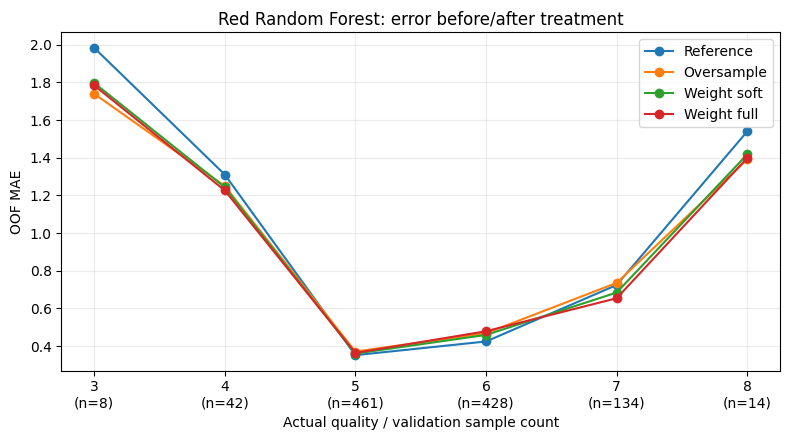

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,8,1.9846,4.9846,Red,RF,Reference
1,4.0,42,1.3109,5.3109,Red,RF,Reference
2,5.0,461,0.3515,5.3230,Red,RF,Reference
3,6.0,428,0.4241,5.7688,Red,RF,Reference
4,7.0,134,0.7241,6.2856,Red,RF,Reference
5,8.0,14,1.5406,6.4594,Red,RF,Reference
6,3.0,8,1.7402,4.7402,Red,RF,Oversample
7,4.0,42,1.2501,5.2501,Red,RF,Oversample
8,5.0,461,0.3706,5.2892,Red,RF,Oversample
9,6.0,428,0.4682,5.7545,Red,RF,Oversample


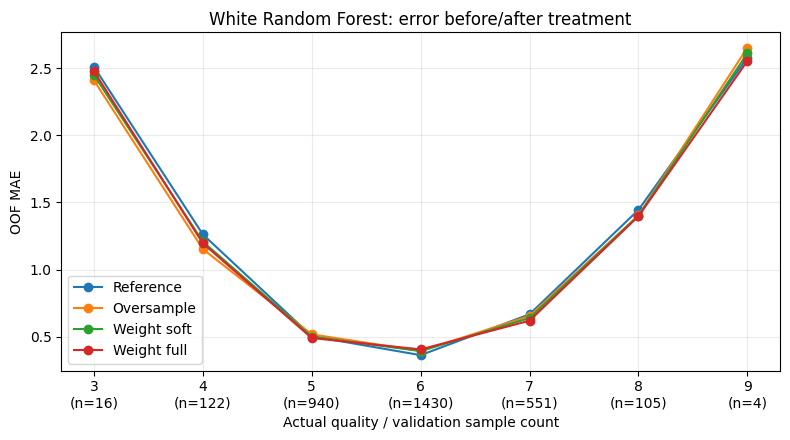

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,16,2.5114,5.5114,White,RF,Reference
1,4.0,122,1.2622,5.2622,White,RF,Reference
2,5.0,940,0.5034,5.4808,White,RF,Reference
3,6.0,1430,0.3624,5.9329,White,RF,Reference
4,7.0,551,0.6669,6.3448,White,RF,Reference
5,8.0,105,1.4447,6.5553,White,RF,Reference
6,9.0,4,2.5797,6.4203,White,RF,Reference
7,3.0,16,2.4104,5.4104,White,RF,Oversample
8,4.0,122,1.1526,5.1327,White,RF,Oversample
9,5.0,940,0.5174,5.4553,White,RF,Oversample


In [ ]:
score_comparison("Red","RF",['Reference', 'Oversample', 'Weight soft', 'Weight full'],"Red Random Forest: error before/after treatment")
score_comparison("White","RF",['Reference', 'Oversample', 'Weight soft', 'Weight full'],"White Random Forest: error before/after treatment")

### 8.3 KNN — rare-score treatments
Sample weighting is outside the defined experiment for this model; compare original and oversampled training only.

#### Red wine — calculations

In [ ]:
red_knn_rare = [red_knn_reference]
for treatment in ['Oversample']:
    red_knn_rare.append(condition("Red","KNN",variant=treatment,treatment=treatment))
display(pd.DataFrame(red_knn_rare).round(4))

Completed: Red | KNN | Oversample


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,KNN,Reference,raw,Original,standard,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664,0.0266
1,Red,KNN,Oversample,raw,Oversample,standard,0.5733,0.7553,0.1605,1.0452,1.3873,0.4842,0.7757,0.0230


#### White wine — calculations

In [ ]:
white_knn_rare = [white_knn_reference]
for treatment in ['Oversample']:
    white_knn_rare.append(condition("White","KNN",variant=treatment,treatment=treatment))
display(pd.DataFrame(white_knn_rare).round(4))

Completed: White | KNN | Oversample


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,KNN,Reference,raw,Original,standard,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651,0.0104
1,White,KNN,Oversample,raw,Oversample,standard,0.6051,0.8036,0.1856,1.3405,1.4206,0.5071,0.6611,0.0186


#### Combined results
Read overall, macro and rare-score MAE together. A lower rare-score error can come at a cost to typical wines; report both sides of the trade-off.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5158,0.6655,0.3483,1.1102,1.5280,0.4051,0.7664
5,White,KNN,Reference,0.5536,0.7203,0.3459,1.3712,1.5494,0.4239,0.6651
60,Red,KNN,Oversample,0.5733,0.7553,0.1605,1.0452,1.3873,0.4842,0.7757
61,White,KNN,Oversample,0.6051,0.8036,0.1856,1.3405,1.4206,0.5071,0.6611


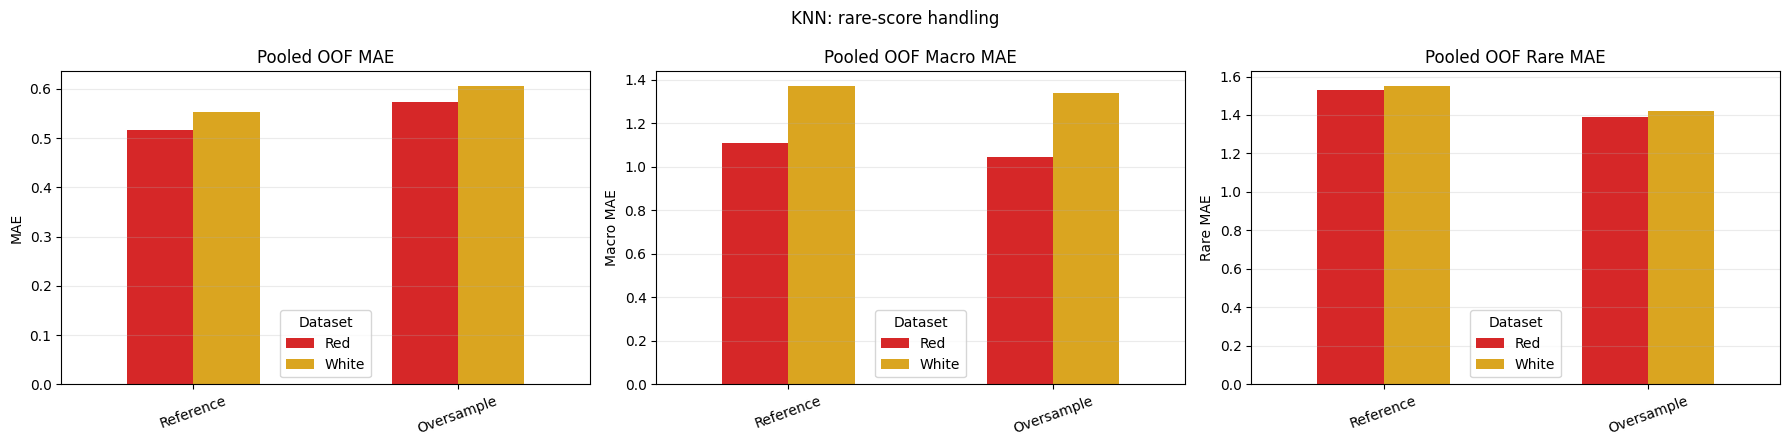

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
4,Red,KNN,Reference,0.5092,0.6651,0.3406,1.1350,1.4478,0.4062,0.7505
5,White,KNN,Reference,0.5563,0.7215,0.3438,1.3372,1.5924,0.4303,0.6323
60,Red,KNN,Oversample,0.5625,0.7615,0.1356,1.1288,1.3660,0.4652,0.8304
61,White,KNN,Oversample,0.5913,0.7853,0.2225,1.2785,1.4151,0.4950,0.6352


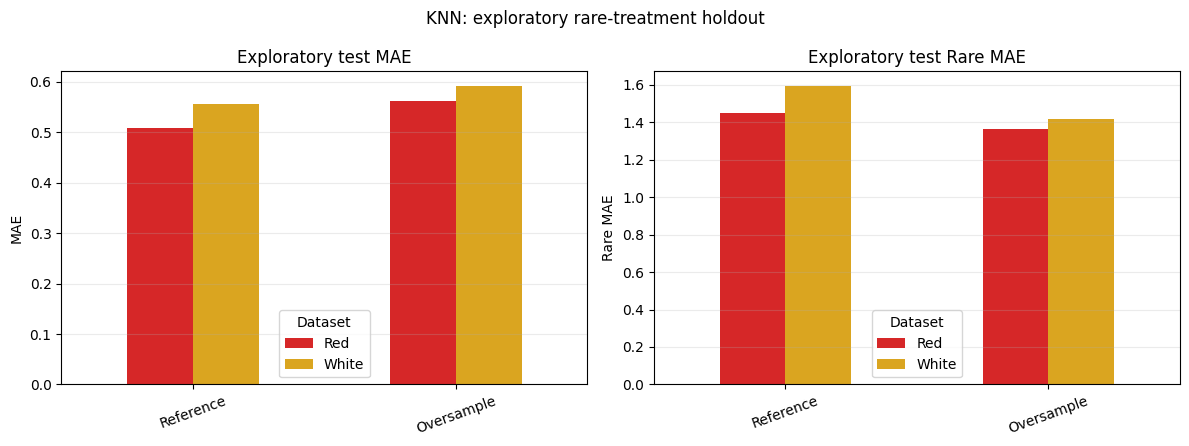

In [ ]:
comparison("KNN: rare-score handling","KNN",['Reference', 'Oversample'],metrics=("MAE","Macro MAE","Rare MAE"))
if RUN_HOLDOUT:
    comparison("KNN: exploratory rare-treatment holdout","KNN",['Reference', 'Oversample'],metrics=("MAE","Rare MAE"),holdout=True)

#### Errors at each actual quality score
These curves use pooled OOF predictions. Each x-axis label shows how many original validation observations support that score; duplicated fitting records do not increase evaluation counts.

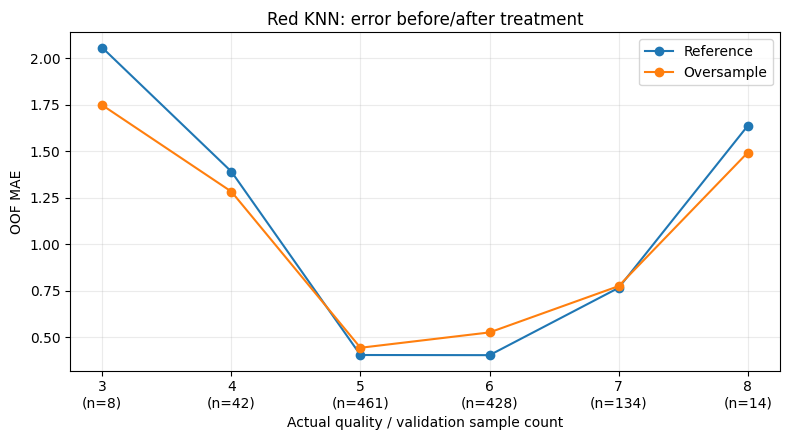

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,8,2.0566,5.0566,Red,KNN,Reference
1,4.0,42,1.3910,5.3910,Red,KNN,Reference
2,5.0,461,0.4055,5.3897,Red,KNN,Reference
3,6.0,428,0.4047,5.7747,Red,KNN,Reference
4,7.0,134,0.7664,6.2358,Red,KNN,Reference
5,8.0,14,1.6370,6.3630,Red,KNN,Reference
6,3.0,8,1.7476,4.7476,Red,KNN,Oversample
7,4.0,42,1.2834,5.1429,Red,KNN,Oversample
8,5.0,461,0.4444,5.2960,Red,KNN,Oversample
9,6.0,428,0.5269,5.7567,Red,KNN,Oversample


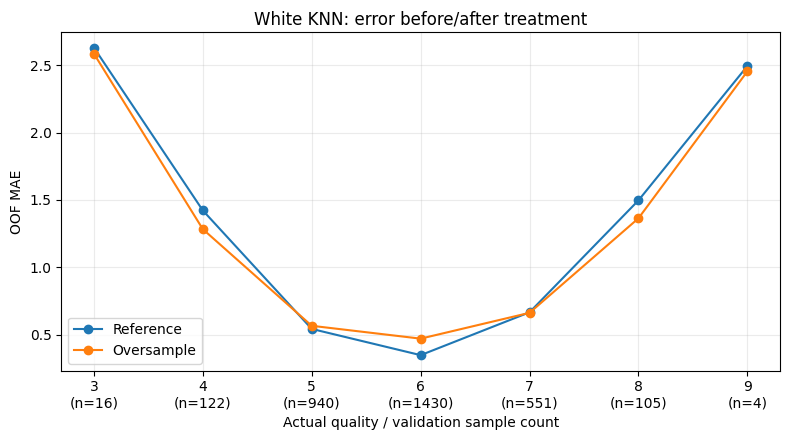

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,16,2.6316,5.6316,White,KNN,Reference
1,4.0,122,1.4218,5.4218,White,KNN,Reference
2,5.0,940,0.5415,5.5316,White,KNN,Reference
3,6.0,1430,0.3465,5.9437,White,KNN,Reference
4,7.0,551,0.6651,6.3422,White,KNN,Reference
5,8.0,105,1.4968,6.5032,White,KNN,Reference
6,9.0,4,2.4953,6.5047,White,KNN,Reference
7,3.0,16,2.5866,5.5866,White,KNN,Oversample
8,4.0,122,1.2828,5.2464,White,KNN,Oversample
9,5.0,940,0.5647,5.4464,White,KNN,Oversample


In [ ]:
score_comparison("Red","KNN",['Reference', 'Oversample'],"Red KNN: error before/after treatment")
score_comparison("White","KNN",['Reference', 'Oversample'],"White KNN: error before/after treatment")

### 8.4 MLP Neural Network — rare-score treatments
Sample weighting is outside the defined experiment for this model; compare original and oversampled training only.

#### Red wine — calculations

In [ ]:
red_mlp_rare = [red_mlp_reference]
for treatment in ['Oversample']:
    red_mlp_rare.append(condition("Red","MLP",variant=treatment,treatment=treatment))
display(pd.DataFrame(red_mlp_rare).round(4))

Completed: Red | MLP | Oversample


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,Red,MLP,Reference,raw,Original,standard,0.5421,0.7056,0.2673,1.090,1.4919,0.4419,0.7534,0.0373
1,Red,MLP,Oversample,raw,Oversample,standard,0.5849,0.7523,0.1672,1.009,1.2642,0.5097,0.7587,0.0309


#### White wine — calculations

In [ ]:
white_mlp_rare = [white_mlp_reference]
for treatment in ['Oversample']:
    white_mlp_rare.append(condition("White","MLP",variant=treatment,treatment=treatment))
display(pd.DataFrame(white_mlp_rare).round(4))

Completed: White | MLP | Oversample


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Fold MAE std
0,White,MLP,Reference,raw,Original,standard,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803,0.0113
1,White,MLP,Oversample,raw,Oversample,standard,0.6344,0.8228,0.1463,1.3278,1.3578,0.5439,0.6996,0.0156


#### Combined results
Read overall, macro and rare-score MAE together. A lower rare-score error can come at a cost to typical wines; report both sides of the trade-off.

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5421,0.7056,0.2673,1.0900,1.4919,0.4419,0.7534
7,White,MLP,Reference,0.5669,0.7333,0.3219,1.2959,1.4142,0.4522,0.6803
62,Red,MLP,Oversample,0.5849,0.7523,0.1672,1.0090,1.2642,0.5097,0.7587
63,White,MLP,Oversample,0.6344,0.8228,0.1463,1.3278,1.3578,0.5439,0.6996


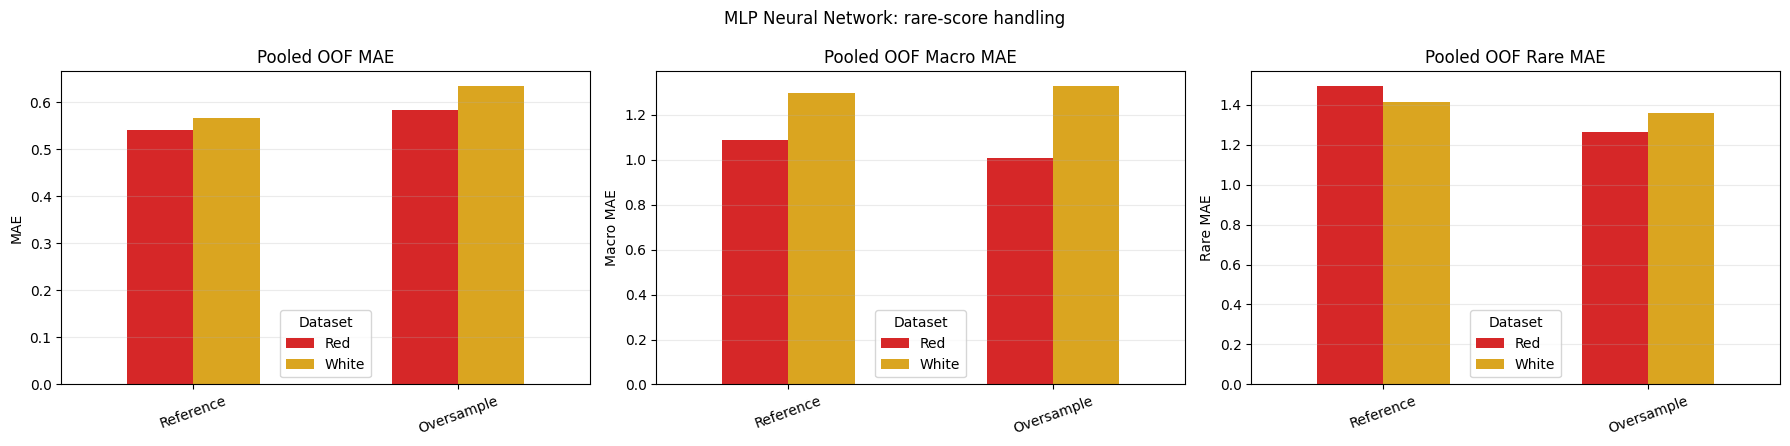

,Dataset,Model,Variant,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE
6,Red,MLP,Reference,0.5138,0.6783,0.3142,1.1329,1.3644,0.4188,0.7429
7,White,MLP,Reference,0.5797,0.7440,0.3022,1.2560,1.5194,0.4534,0.7003
62,Red,MLP,Oversample,0.5568,0.7215,0.2240,1.0967,1.2481,0.4795,0.7436
63,White,MLP,Oversample,0.6450,0.8506,0.0879,1.0846,1.2232,0.5495,0.7954


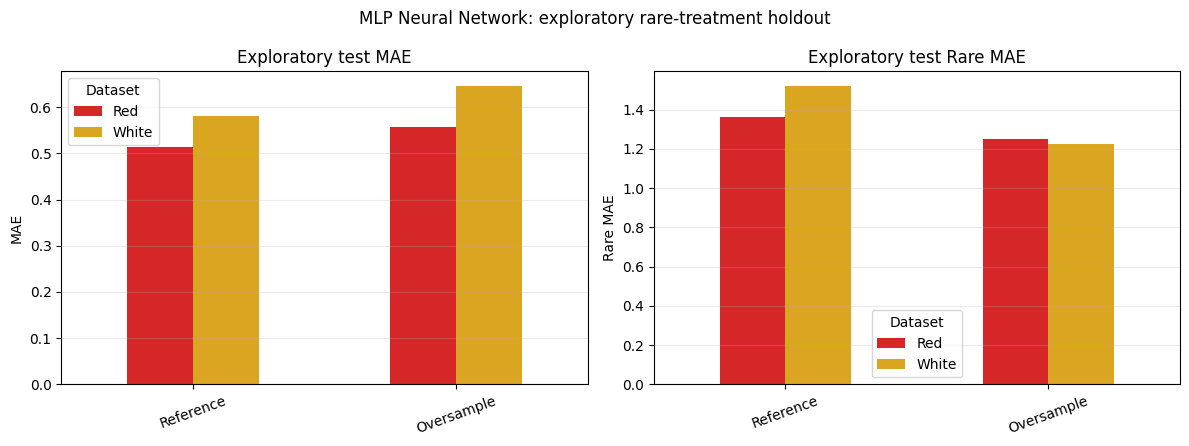

In [ ]:
comparison("MLP Neural Network: rare-score handling","MLP",['Reference', 'Oversample'],metrics=("MAE","Macro MAE","Rare MAE"))
if RUN_HOLDOUT:
    comparison("MLP Neural Network: exploratory rare-treatment holdout","MLP",['Reference', 'Oversample'],metrics=("MAE","Rare MAE"),holdout=True)

#### Errors at each actual quality score
These curves use pooled OOF predictions. Each x-axis label shows how many original validation observations support that score; duplicated fitting records do not increase evaluation counts.

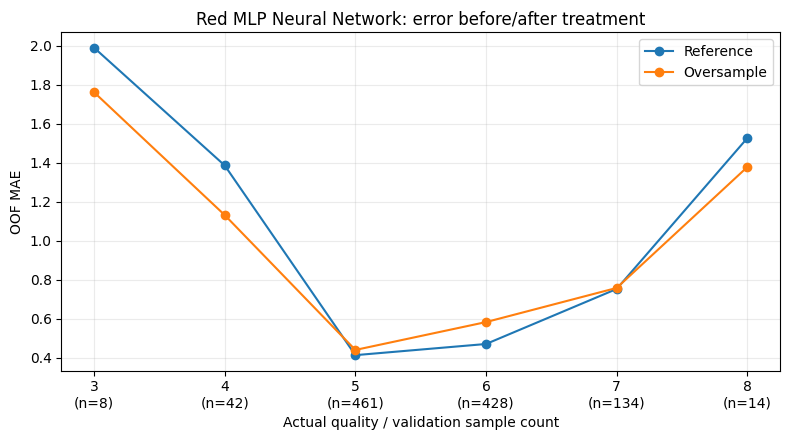

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,8,1.9889,4.9889,Red,MLP,Reference
1,4.0,42,1.3859,5.3859,Red,MLP,Reference
2,5.0,461,0.4144,5.3439,Red,MLP,Reference
3,6.0,428,0.4715,5.7654,Red,MLP,Reference
4,7.0,134,0.7534,6.2860,Red,MLP,Reference
5,8.0,14,1.5260,6.4740,Red,MLP,Reference
6,3.0,8,1.7608,4.7608,Red,MLP,Oversample
7,4.0,42,1.1318,5.1318,Red,MLP,Oversample
8,5.0,461,0.4410,5.2740,Red,MLP,Oversample
9,6.0,428,0.5838,5.7499,Red,MLP,Oversample


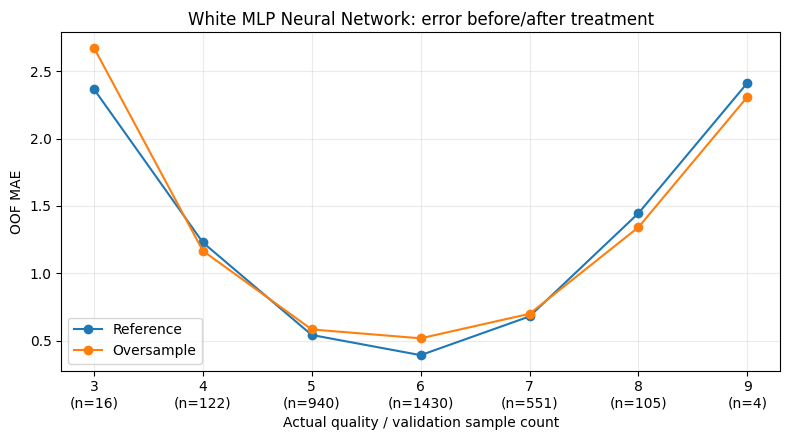

,Quality,Samples,MAE,Mean_prediction,Dataset,Model,Variant
0,3.0,16,2.3674,5.3327,White,MLP,Reference
1,4.0,122,1.2292,5.2170,White,MLP,Reference
2,5.0,940,0.5425,5.4867,White,MLP,Reference
3,6.0,1430,0.3928,5.9309,White,MLP,Reference
4,7.0,551,0.6803,6.3504,White,MLP,Reference
5,8.0,105,1.4460,6.5540,White,MLP,Reference
6,9.0,4,2.4129,6.5871,White,MLP,Reference
7,3.0,16,2.6747,5.6747,White,MLP,Oversample
8,4.0,122,1.1674,5.1416,White,MLP,Oversample
9,5.0,940,0.5836,5.4310,White,MLP,Oversample


In [ ]:
score_comparison("Red","MLP",['Reference', 'Oversample'],"Red MLP Neural Network: error before/after treatment")
score_comparison("White","MLP",['Reference', 'Oversample'],"White MLP Neural Network: error before/after treatment")

### 8.5 Verify actual training counts after oversampling
Inspect before/after counts and repetition factors separately by dataset, model and fold. MLP has a smaller fitting partition because its inner validation set is excluded. Extremely large repetition factors are a limitation and do not mean many independent rare wines were observed.

In [ ]:
sampling_counts=pd.DataFrame(ALL_COUNTS)
display(sampling_counts[sampling_counts.Treatment=="Oversample"].round(3))

,Dataset,Model,Variant,Representation,Treatment,Scaling,Fold,Quality,Before,After,Factor
1536,Red,LR,Oversample,raw,Oversample,Not applied,1,3.0,7,86,12.286
1537,Red,LR,Oversample,raw,Oversample,Not applied,1,4.0,37,86,2.324
1538,Red,LR,Oversample,raw,Oversample,Not applied,1,5.0,369,369,1.000
1539,Red,LR,Oversample,raw,Oversample,Not applied,1,6.0,336,336,1.000
1540,Red,LR,Oversample,raw,Oversample,Not applied,1,7.0,109,109,1.000
...,...,...,...,...,...,...,...,...,...,...,...
2043,White,MLP,Oversample,raw,Oversample,standard,5,5.0,639,639,1.000
2044,White,MLP,Oversample,raw,Oversample,standard,5,6.0,982,982,1.000
2045,White,MLP,Oversample,raw,Oversample,standard,5,7.0,372,372,1.000
2046,White,MLP,Oversample,raw,Oversample,standard,5,8.0,67,215,3.209


## 9. RF regression versus classification — separately tuned
Both RF approaches are separately tuned using the same 18-configuration grid, training-set MAE objective and identical saved CV partitions. This preserves the separate-tuning experiment from the team notebook while controlling fold differences. RUN_RF_GRID_SEARCH=True in Section 1.1 enables these searches. Read the printed parameters and selection CV MAE for each approach.

This is a focused RF target-formulation experiment, not a conversion of the entire project to classification. Regression's continuous predictions are used for MAE/RMSE; accuracy metrics round them without test-derived clipping. Rounded-regression MAE is additionally shown. Classification can improve one metric while worsening another.

The shared folds are shuffled KFold rather than stratified folds. Some very rare scores can be absent from a fold; conclusions at those scores are limited. These reused selection CV scores are not nested estimates, and the previously inspected test results remain exploratory.


### 9.1 Shared RF formulation helper

In [11]:
def run_rf_formulation(wine):
    Xtr,Xte,ytr,yte=DATASETS[wine]
    params=dict(n_estimators=RF_TREES,max_depth=None if wine=="Red" else 20,
                min_samples_leaf=3,random_state=SEED,n_jobs=-1)
    candidates={"Regression":RandomForestRegressor(**params),"Classification":RandomForestClassifier(**params)}
    fitted,rows,score_parts={},[],[]
    for approach,estimator in candidates.items():
        if RUN_RF_GRID_SEARCH:
            grid={"n_estimators":[20] if QUICK_MODE else [100,200],
                  "max_depth":[None,10,20],"min_samples_leaf":[1,3,5]}
            search=GridSearchCV(estimator.set_params(n_jobs=1),grid,scoring="neg_mean_absolute_error",
                                cv=SPLITS[wine],n_jobs=-1)
            search.fit(Xtr,ytr);estimator=search.best_estimator_
            print(wine,approach,search.best_params_,"Selection CV MAE",-search.best_score_)
        else:estimator.fit(Xtr,ytr)
        fitted[approach]=estimator
        pred=estimator.predict(Xte);rounded=np.rint(pred)
        rows.append({"Dataset":wine,"Approach":approach,"Search":RUN_RF_GRID_SEARCH,
            **prediction_metrics(yte,pred),"Exact accuracy":accuracy_score(yte,rounded),
            "Within one accuracy":np.mean(np.abs(yte.to_numpy()-rounded)<=1),
            "Rounded prediction MAE":mean_absolute_error(yte,rounded)})
        score_parts.append(by_quality(yte,pred).assign(Dataset=wine,Approach=approach))
        print(wine,approach,"predicted values:",np.unique(pred) if approach=="Classification" else (pred.min(),pred.max()))
    return pd.DataFrame(rows),pd.concat(score_parts,ignore_index=True),fitted

### 9.2 Red wine — calculations

In [12]:
if RUN_HOLDOUT:
    red_rf_formulation,red_rf_scores,red_rf_fits=run_rf_formulation("Red")
    display(red_rf_formulation.round(4));display(red_rf_scores.round(4))
else:print("Holdout experiments disabled.")

Red Regression {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200} Selection CV MAE 0.4905045184963198
Red Regression predicted values: (np.float64(4.469370129870131), np.float64(7.058543109668109))


Red Classification {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 100} Selection CV MAE 0.42596710776645674
Red Classification predicted values: [5 6 7]


,Dataset,Approach,Search,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Exact accuracy,Within one accuracy,Rounded prediction MAE
0,Red,Regression,True,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226,0.6029,0.9743,0.4228
1,Red,Classification,True,0.4044,0.7019,0.2656,1.1211,1.5000,0.2780,0.7273,0.6360,0.9632,0.4044


,Quality,Samples,MAE,Mean_prediction,Dataset,Approach
0,3,2,2.0783,5.0783,Red,Regression
1,4,11,1.0303,5.0303,Red,Regression
2,5,116,0.3724,5.3599,Red,Regression
3,6,107,0.4224,5.7867,Red,Regression
4,7,33,0.7226,6.2845,Red,Regression
5,8,3,1.3657,6.6343,Red,Regression
6,3,2,2.5000,5.5000,Red,Classification
7,4,11,1.2727,5.2727,Red,Classification
8,5,116,0.2328,5.2328,Red,Classification
9,6,107,0.3271,5.7850,Red,Classification


### 9.3 White wine — calculations

In [13]:
if RUN_HOLDOUT:
    white_rf_formulation,white_rf_scores,white_rf_fits=run_rf_formulation("White")
    display(white_rf_formulation.round(4));display(white_rf_scores.round(4))

White Regression {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 200} Selection CV MAE 0.541368278387931
White Regression predicted values: (np.float64(4.174321373071374), np.float64(7.287332702020202))


White Classification {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200} Selection CV MAE 0.489601367480477
White Classification predicted values: [4 5 6 7 8]


,Dataset,Approach,Search,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Exact accuracy,Within one accuracy,Rounded prediction MAE
0,White,Regression,True,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633,0.5750,0.9546,0.4741
1,White,Classification,True,0.4880,0.7772,0.2385,1.2696,1.4355,0.3305,0.7391,0.5662,0.9496,0.4880


,Quality,Samples,MAE,Mean_prediction,Dataset,Approach
0,3,4,2.6010,5.6010,White,Regression
1,4,31,1.1181,5.1181,White,Regression
2,5,235,0.5283,5.5115,White,Regression
3,6,358,0.3534,5.9028,White,Regression
4,7,138,0.6633,6.3471,White,Regression
5,8,26,1.5775,6.4225,White,Regression
6,9,1,2.0215,6.9785,White,Regression
7,3,4,2.7500,5.7500,White,Classification
8,4,31,1.1290,5.1290,White,Classification
9,5,235,0.4213,5.3957,White,Classification


### 9.4 Combined results
These exploratory holdout results describe numerical-error and discrete-accuracy trade-offs. Low score counts limit conclusions about extremes.

,Dataset,Approach,Search,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,Exact accuracy,Within one accuracy,Rounded prediction MAE
0,Red,Regression,True,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226,0.6029,0.9743,0.4228
1,Red,Classification,True,0.4044,0.7019,0.2656,1.1211,1.5000,0.2780,0.7273,0.6360,0.9632,0.4044
2,White,Regression,True,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633,0.5750,0.9546,0.4741
3,White,Classification,True,0.4880,0.7772,0.2385,1.2696,1.4355,0.3305,0.7391,0.5662,0.9496,0.4880


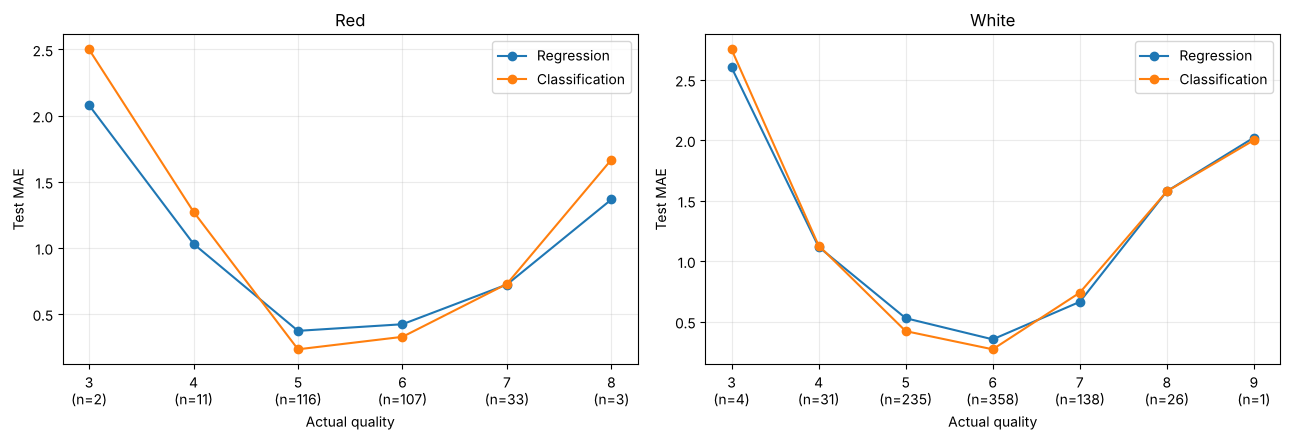

In [14]:
if RUN_HOLDOUT:
    rf_formulation_summary=pd.concat([red_rf_formulation,white_rf_formulation],ignore_index=True)
    rf_by_score=pd.concat([red_rf_scores,white_rf_scores],ignore_index=True)
    display(rf_formulation_summary.round(4))
    rf_formulation_summary.to_csv(OUTPUT/"rf_formulation_summary.csv",index=False)
    rf_by_score.to_csv(OUTPUT/"rf_formulation_error_by_score.csv",index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,4.5))
    for ax,wine in zip(axes,["Red","White"]):
        for approach in ["Regression","Classification"]:
            d=rf_by_score[(rf_by_score.Dataset==wine)&(rf_by_score.Approach==approach)]
            ax.plot(d.Quality,d.MAE,marker="o",label=approach)
        d=rf_by_score[(rf_by_score.Dataset==wine)&(rf_by_score.Approach=="Regression")]
        ax.set_xticks(d.Quality);ax.set_xticklabels([f"{q:g}\n(n={n})" for q,n in zip(d.Quality,d.Samples)])
        ax.set_title(wine);ax.set_xlabel("Actual quality");ax.set_ylabel("Test MAE");ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.savefig(OUTPUT/"rf_formulation_errors.png",dpi=200);plt.show();plt.close("all")

## 10. RF feature importance
Permutation importance measures the increase in test MAE when a feature is shuffled. Correlated features may substitute for one another. Impurity importance is a different measure and can favour features with more split opportunities. Neither measure proves causation; repeat standard deviation is not a confidence interval. These test explanations must not guide subsequent feature selection while claiming independent test evaluation.

### 10.1 Shared importance helper

In [15]:
def rf_importance_table(wine,fitted):
    Xtr,Xte,ytr,yte=DATASETS[wine]
    perm=permutation_importance(fitted,Xte,yte,scoring="neg_mean_absolute_error",
        n_repeats=3 if QUICK_MODE else 20,random_state=SEED,n_jobs=-1)
    return pd.DataFrame({"Dataset":wine,"Feature":Xtr.columns,
        "Impurity importance":fitted.feature_importances_,
        "Permutation MAE increase":perm.importances_mean,
        "Permutation repeat std":perm.importances_std}).sort_values("Permutation MAE increase",ascending=False)

### 10.2 Red wine — calculations

In [16]:
if RUN_HOLDOUT:
    red_rf_importance=rf_importance_table("Red",red_rf_fits["Regression"])
    display(red_rf_importance.round(4))

,Dataset,Feature,Impurity importance,Permutation MAE increase,Permutation repeat std
10,Red,alcohol,0.2939,0.1222,0.0142
9,Red,sulphates,0.1577,0.0626,0.0103
1,Red,volatile acidity,0.1484,0.0339,0.0080
6,Red,total sulfur dioxide,0.0695,0.0214,0.0047
7,Red,density,0.0460,0.0066,0.0016
5,Red,free sulfur dioxide,0.0436,0.0062,0.0028
2,Red,citric acid,0.0466,0.0053,0.0027
8,Red,pH,0.0500,0.0051,0.0025
3,Red,residual sugar,0.0445,0.0028,0.0023
4,Red,chlorides,0.0580,0.0023,0.0023


### 10.3 White wine — calculations

In [17]:
if RUN_HOLDOUT:
    white_rf_importance=rf_importance_table("White",white_rf_fits["Regression"])
    display(white_rf_importance.round(4))

,Dataset,Feature,Impurity importance,Permutation MAE increase,Permutation repeat std
10,White,alcohol,0.2874,0.1572,0.0153
1,White,volatile acidity,0.1189,0.0530,0.0080
5,White,free sulfur dioxide,0.1228,0.0397,0.0070
4,White,chlorides,0.0524,0.0146,0.0027
8,White,pH,0.0735,0.0126,0.0040
3,White,residual sugar,0.0600,0.0121,0.0024
6,White,total sulfur dioxide,0.0643,0.0106,0.0025
2,White,citric acid,0.0542,0.0083,0.0022
0,White,fixed acidity,0.0549,0.0080,0.0023
9,White,sulphates,0.0605,0.0053,0.0020


### 10.4 Combined feature-importance comparison

,Dataset,Feature,Impurity importance,Permutation MAE increase,Permutation repeat std
0,Red,alcohol,0.2939,0.1222,0.0142
1,Red,sulphates,0.1577,0.0626,0.0103
2,Red,volatile acidity,0.1484,0.0339,0.0080
3,Red,total sulfur dioxide,0.0695,0.0214,0.0047
4,Red,density,0.0460,0.0066,0.0016
5,Red,free sulfur dioxide,0.0436,0.0062,0.0028
6,Red,citric acid,0.0466,0.0053,0.0027
7,Red,pH,0.0500,0.0051,0.0025
8,Red,residual sugar,0.0445,0.0028,0.0023
9,Red,chlorides,0.0580,0.0023,0.0023


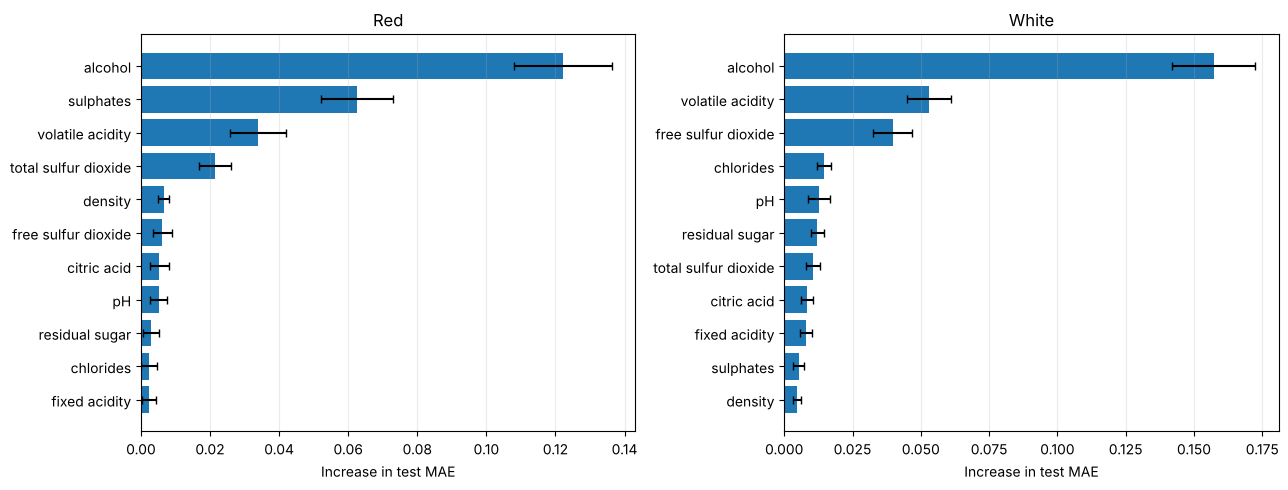

In [18]:
if RUN_HOLDOUT:
    rf_importance=pd.concat([red_rf_importance,white_rf_importance],ignore_index=True)
    rf_importance.to_csv(OUTPUT/"rf_feature_importance.csv",index=False)
    display(rf_importance.round(4))
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,wine in zip(axes,["Red","White"]):
        part=rf_importance[rf_importance.Dataset==wine].sort_values("Permutation MAE increase")
        ax.barh(part.Feature,part["Permutation MAE increase"],xerr=part["Permutation repeat std"],capsize=3)
        ax.set_title(wine);ax.set_xlabel("Increase in test MAE");ax.grid(axis="x",alpha=.25)
    plt.tight_layout();plt.savefig(OUTPUT/"rf_feature_importance.png",dpi=200);plt.show();plt.close("all")

## 11. Consolidated findings and export
### 11.1 All completed conditions
These combined tables are generated from the section-by-section calculations. Negative changes indicate lower observed error relative to the corresponding original-distribution selected reference. Do not automatically label small differences significant or equivalent. Explain what changed, why it might matter, what happened and what the evidence supports.

In [ ]:
save_progress()
cv_summary=pd.DataFrame(ALL_CV_ROWS)
reference=cv_summary.query("Variant=='Reference'")[["Dataset","Model","MAE","Macro MAE","Rare MAE"]]
changes=cv_summary.merge(reference,on=["Dataset","Model"],suffixes=(""," reference"))
for metric in ["MAE","Macro MAE","Rare MAE"]:
    changes[f"Change in {metric}"]=changes[metric]-changes[f"{metric} reference"]
display(changes[["Dataset","Model","Variant","MAE","Macro MAE","Rare MAE",
    "Change in MAE","Change in Macro MAE","Change in Rare MAE"]].round(4))
changes.to_csv(OUTPUT/"changes_from_reference.csv",index=False)
score_exports=[]
for tags,part in pd.DataFrame(ALL_OOF_ROWS).groupby(["Dataset","Model","Variant"],sort=False):
    wine,model,variant=tags
    score_exports.append(by_quality(part.Quality.to_numpy(),part.Prediction.to_numpy()).assign(
        Dataset=wine,Model=model,Variant=variant))
pd.concat(score_exports,ignore_index=True).to_csv(OUTPUT/"all_oof_error_by_score.csv",index=False)
print("Completed conditions:",len(cv_summary),"| expected full matrix: 64 rows (32 per dataset).")
assert len(cv_summary)==64,"Some experiment cells were skipped. Run all sections in order."
if RUN_HOLDOUT:display(pd.DataFrame(ALL_TEST_ROWS).round(4))

,Dataset,Model,Variant,MAE,Macro MAE,Rare MAE,Change in MAE,Change in Macro MAE,Change in Rare MAE
0,Red,LR,Reference,0.5160,1.0880,1.4906,0.0000,0.0000,0.0000
1,White,LR,Reference,0.5776,1.4217,1.5839,0.0000,0.0000,0.0000
2,Red,RF,Reference,0.4905,1.0560,1.4454,0.0000,0.0000,0.0000
3,White,RF,Reference,0.5414,1.3330,1.4420,0.0000,0.0000,0.0000
4,Red,KNN,Reference,0.5158,1.1102,1.5280,0.0000,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...
59,White,RF,Weight full,0.5441,1.3058,1.3868,0.0028,-0.0272,-0.0553
60,Red,KNN,Oversample,0.5733,1.0452,1.3873,0.0575,-0.0650,-0.1407
61,White,KNN,Oversample,0.6051,1.3405,1.4206,0.0515,-0.0308,-0.1288
62,Red,MLP,Oversample,0.5849,1.0090,1.2642,0.0427,-0.0810,-0.2277


Completed conditions: 64 | expected full matrix: 64 rows (32 per dataset).


,Dataset,Model,Variant,Representation,Treatment,Scaling,MAE,RMSE,R2,Macro MAE,Rare MAE,Typical MAE,Score 7 MAE,MLP best epoch
0,Red,LR,Reference,raw,Original,Not applied,0.5066,0.6523,0.3657,1.1082,1.3838,0.3998,0.8027,NaN
1,White,LR,Reference,raw,Original,Not applied,0.5867,0.7608,0.2703,1.3764,1.6438,0.4448,0.7217,NaN
2,Red,RF,Reference,raw,Original,Not applied,0.4846,0.6316,0.4054,0.9986,1.2242,0.3964,0.7226,NaN
3,White,RF,Reference,raw,Original,Not applied,0.5426,0.6984,0.3850,1.2662,1.4210,0.4227,0.6633,NaN
4,Red,KNN,Reference,raw,Original,standard,0.5092,0.6651,0.3406,1.1350,1.4478,0.4062,0.7505,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,White,RF,Weight full,raw,Weight full,Not applied,0.5365,0.6885,0.4024,1.1637,1.3213,0.4395,0.6009,NaN
60,Red,KNN,Oversample,raw,Oversample,standard,0.5625,0.7615,0.1356,1.1288,1.3660,0.4652,0.8304,NaN
61,White,KNN,Oversample,raw,Oversample,standard,0.5913,0.7853,0.2225,1.2785,1.4151,0.4950,0.6352,NaN
62,Red,MLP,Oversample,raw,Oversample,standard,0.5568,0.7215,0.2240,1.0967,1.2481,0.4795,0.7436,209.0


### 11.2 Download tables and figures
The ZIP contains data tables, figures, split identities, actual training oversampling counts, fold preprocessing choices and environment settings. Quick-mode outputs are execution checks and must not be used as final report evidence.

In [ ]:
import shutil
archive=shutil.make_archive("wine_section_outputs","zip",root_dir=OUTPUT)
print("Results archive:",archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Outside Colab: download the ZIP from your working directory.")